# Santander churn — discrete-time hazard model

**Step 1: Download data** from the Kaggle *Santander Product Recommendation* competition (requires rules accepted on Kaggle and `~/.kaggle/kaggle.json`).

In [1]:
# Install the Kaggle API client into this kernel's environment (one-time).
# (%pip fails here because sys.executable carries a Windows "\\?\" prefix, so call pip directly.)
import subprocess, sys
PY = sys.executable.replace("\\\\?\\", "")
r = subprocess.run([PY, "-m", "pip", "install", "-q", "kaggle"], capture_output=True, text=True)
print("pip exit code:", r.returncode)

pip exit code: 0


In [2]:
# Download the training file (monthly snapshots Jan-2015 .. May-2016) into ./data
from pathlib import Path
from kaggle.api.kaggle_api_extended import KaggleApi

COMP = "santander-product-recommendation"
DATA = Path("data"); DATA.mkdir(exist_ok=True)

api = KaggleApi(); api.authenticate()
print([f.name for f in api.competition_list_files(COMP).files])

api.competition_download_file(COMP, "train_ver2.csv.zip", path=str(DATA), quiet=False)
sorted(p.name for p in DATA.iterdir())

['sample_submission.csv.zip', 'test_ver2.csv.zip', 'train_ver2.csv.zip']
train_ver2.csv.zip: Skipping, found more recently modified local copy (use --force to force download)


['train_sample10.parquet', 'train_ver2.csv', 'train_ver2.csv.zip']

In [3]:
# Unzip and sanity-check: months covered, rows, and distinct customers
import zipfile, pandas as pd

zip_path = DATA / "train_ver2.csv.zip"
csv_path = DATA / "train_ver2.csv"
if not csv_path.exists():
    with zipfile.ZipFile(zip_path) as z:
        z.extractall(DATA)
print(f"{csv_path.name}: {csv_path.stat().st_size/1e9:.2f} GB")

# Read just the panel keys for a quick check (full file is ~13.6M rows)
keys = pd.read_csv(csv_path, usecols=["fecha_dato", "ncodpers"])
summary = (keys.groupby("fecha_dato")["ncodpers"].nunique()
               .rename("customers").to_frame())
print(f"rows: {len(keys):,} | distinct customers: {keys['ncodpers'].nunique():,} | months: {summary.shape[0]}")
summary

train_ver2.csv: 2.29 GB
rows: 13,647,309 | distinct customers: 956,645 | months: 17


,customers
fecha_dato,
2015-01-28,625457
2015-02-28,627394
2015-03-28,629209
2015-04-28,630367
2015-05-28,631957
2015-06-28,632110
2015-07-28,829817
2015-08-28,843201
2015-09-28,865440


In [4]:
# How often do customers actually disappear from the panel month to month?
months = sorted(keys["fecha_dato"].unique())
by_month = {m: set(g) for m, g in keys.groupby("fecha_dato")["ncodpers"]}
exit_rows = []
for m0, m1 in zip(months[:-1], months[1:]):
    a, b = by_month[m0], by_month[m1]
    exit_rows.append({"month": m0, "present": len(a), "gone_next_month": len(a - b),
                      "exit_rate_%": round(100 * len(a - b) / len(a), 3),
                      "new_next_month": len(b - a)})
pd.DataFrame(exit_rows).set_index("month")

,present,gone_next_month,exit_rate_%,new_next_month
month,,,,
2015-01-28,625457,2531,0.405,4468
2015-02-28,627394,2300,0.367,4115
2015-03-28,629209,2511,0.399,3669
2015-04-28,630367,2232,0.354,3822
2015-05-28,631957,3354,0.531,3507
2015-06-28,632110,1861,0.294,199568
2015-07-28,829817,1456,0.175,14840
2015-08-28,843201,1406,0.167,23645
2015-09-28,865440,1750,0.202,28561


In [5]:
import pandas as pd
import numpy as np
df = pd.read_parquet("data/train_sample10.parquet")

In [6]:
df

,fecha_dato,ncodpers,ind_empleado,pais_residencia,sexo,age,fecha_alta,ind_nuevo,antiguedad,indrel,...,ind_hip_fin_ult1,ind_plan_fin_ult1,ind_pres_fin_ult1,ind_reca_fin_ult1,ind_tjcr_fin_ult1,ind_valo_fin_ult1,ind_viv_fin_ult1,ind_nomina_ult1,ind_nom_pens_ult1,ind_recibo_ult1
0,2015-01-28,1050620,N,ES,H,23,2012-08-10,0,35,1,...,0,0,0,0,0,0,0,0,0,0
1,2015-01-28,1050610,N,ES,V,24,2012-08-10,0,35,1,...,0,0,0,0,0,0,0,0,0,0
2,2015-01-28,1050580,N,ES,H,23,2012-08-10,0,35,1,...,0,0,0,0,0,0,0,0,0,0
3,2015-01-28,1050630,N,ES,V,22,2012-08-10,0,35,1,...,0,0,0,0,0,0,0,0,0,0
4,2015-01-28,1050670,N,ES,V,37,2012-08-10,0,35,1,...,0,0,0,0,0,0,0,0,0,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1363964,2016-05-28,1166790,N,ES,H,22,2013-08-14,0,33,1,...,0,0,0,0,0,0,0,0,0,0
1363965,2016-05-28,1166750,N,ES,H,22,2013-08-14,0,33,1,...,0,0,0,0,0,0,0,0,0,1
1363966,2016-05-28,1166740,N,ES,H,22,2013-08-14,0,33,1,...,0,0,0,0,0,0,0,0,0,0
1363967,2016-05-28,1166780,N,ES,H,28,2013-08-14,0,33,1,...,0,0,0,0,0,0,0,0,0,0


In [7]:
# Assert the panel key: (ncodpers, fecha_dato) uniquely identifies a row
KEY = ["ncodpers", "fecha_dato"]

def assert_unique_key(frame, key, label):
    dupes = frame.duplicated(subset=key, keep=False)
    assert not dupes.any(), (
        f"{label}: {dupes.sum():,} rows share a {key} with another row\n"
        f"{frame.loc[dupes, key].head()}"
    )
    assert frame[key].notna().all().all(), f"{label}: key has missing values"
    print(f"{label}: OK, {len(frame):,} rows, {len(frame):,} unique {key} pairs")

assert_unique_key(keys, KEY, "Full file (all customers)")
assert_unique_key(df, KEY, "10% sample (df)")

Full file (all customers): OK, 13,647,309 rows, 13,647,309 unique ['ncodpers', 'fecha_dato'] pairs
10% sample (df): OK, 1,363,969 rows, 1,363,969 unique ['ncodpers', 'fecha_dato'] pairs


In [8]:
df.shape

(1363969, 48)

In [9]:
# Number of unique (ncodpers, fecha_dato) combinations vs. total rows in df
n_rows = len(df)
n_unique = df[["ncodpers", "fecha_dato"]].drop_duplicates().shape[0]

print(f"rows in df:                          {n_rows:,}")
print(f"unique (ncodpers, fecha_dato) pairs: {n_unique:,}")
print("unique key" if n_rows == n_unique else f"{n_rows - n_unique:,} duplicate rows")

rows in df:                          1,363,969
unique (ncodpers, fecha_dato) pairs: 1,363,969
unique key


In [10]:
# Candidate churn definitions: how often does each happen, and do they agree?
PROD = [c for c in df.columns if c.endswith("ult1")]
p = df.sort_values(["ncodpers", "fecha_dato"]).copy()
p["n_prod"] = p[PROD].fillna(0).sum(axis=1).astype(int)
p["t"] = p["fecha_dato"].rank(method="dense").astype(int)          # 1..17
T_LAST = p["t"].max()

g = p.groupby("ncodpers")
p["last_t"] = g["t"].transform("max")
nxt = g[["t", "n_prod", "tiprel_1mes", "indrel", "ind_actividad_cliente"]].shift(-1)

at_risk = p["t"] < T_LAST                                            # need a next month to observe
p["ev_exit"]   = at_risk & (p["t"] == p["last_t"])                   # A: never seen again
p["ev_zero"]   = at_risk & (p["n_prod"] > 0) & (nxt["n_prod"] == 0) & (nxt["t"] == p["t"] + 1)   # B: drops to 0 products
p["ev_flag"]   = at_risk & (p["tiprel_1mes"] != "P") & (p["indrel"] != 99) & (
                 (nxt["tiprel_1mes"] == "P") | (nxt["indrel"] == 99))                           # C: bank status flag
p["ev_dormant"] = at_risk & (p["ind_actividad_cliente"] == 1) & (nxt["ind_actividad_cliente"] == 0)  # D: active -> inactive

risk = p[at_risk]
summary = pd.DataFrame({
    "events": [risk[c].sum() for c in ["ev_exit", "ev_zero", "ev_flag", "ev_dormant"]],
    "monthly_rate_%": [round(100 * risk[c].mean(), 3) for c in ["ev_exit", "ev_zero", "ev_flag", "ev_dormant"]],
}, index=["A: exits panel", "B: drops to 0 products", "C: bank flag (P / indrel 99)", "D: active -> inactive"])
print(f"customer-months at risk: {len(risk):,}")
display(summary)

# What did exiters look like in their last observed month?
last = risk[risk["ev_exit"]]
print("Exiters' last month — products held:", last["n_prod"].describe()[["mean", "50%"]].round(2).to_dict(),
      "| share with 0 products:", round((last["n_prod"] == 0).mean() * 100, 1), "%")
print("Exiters' last month — indrel=99:", round((last["indrel"] == 99).mean() * 100, 1), "%",
      "| active flag=1:", round((last["ind_actividad_cliente"] == 1).mean() * 100, 1), "%")

customer-months at risk: 1,270,902


,events,monthly_rate_%
A: exits panel,2520,0.198
B: drops to 0 products,4223,0.332
C: bank flag (P / indrel 99),1359,0.107
D: active -> inactive,5657,0.446


Exiters' last month — products held: {'mean': 0.16, '50%': 0.0} | share with 0 products: 85.5 %
Exiters' last month — indrel=99: 95.3 % | active flag=1: 6.7 %


## Step 2: Build the target — account closure

**Definition.** For customer *i* in snapshot month *t*:

| `churn` | Condition | Meaning |
|---|---|---|
| **1** | *t* is the customer's **last** month in the panel **and** *t* < May 2016 | Closed: never seen again after *t* |
| **0** | The customer appears again in some later month | Survived month *t* (a one-month gap followed by a return is **not** churn) |
| **&lt;NA&gt;** | *t* = May 2016 (last snapshot) | **Censored**: no later month exists to tell exit from end of data |

Validation: exiters should carry the bank's closure flag (`indrel = 99`) in their final month.

In [11]:
# 2a. Time index and each customer's last observed month
df = df.sort_values(["ncodpers", "fecha_dato"]).reset_index(drop=True)

MONTHS = sorted(df["fecha_dato"].unique())
df["t"] = df["fecha_dato"].map({m: i + 1 for i, m in enumerate(MONTHS)}).astype("int8")   # 1 = Jan-2015 ... 17 = May-2016
T_LAST = int(df["t"].max())

df["last_t"] = df.groupby("ncodpers")["t"].transform("max").astype("int8")

# 2b. Target
df["churn"] = (df["t"] == df["last_t"]).astype("Int8")    # 1 on each customer's last row ...
df.loc[df["t"] == T_LAST, "churn"] = pd.NA                # ... except May-2016, which is censored

df[["ncodpers", "fecha_dato", "t", "last_t", "churn"]].head(20)

,ncodpers,fecha_dato,t,last_t,churn
0,15890,2015-01-28,1,17,0
1,15890,2015-02-28,2,17,0
2,15890,2015-03-28,3,17,0
3,15890,2015-04-28,4,17,0
4,15890,2015-05-28,5,17,0
5,15890,2015-06-28,6,17,0
6,15890,2015-07-28,7,17,0
7,15890,2015-08-28,8,17,0
8,15890,2015-09-28,9,17,0
9,15890,2015-10-28,10,17,0


In [12]:
# 2c. Checks: the target behaves as defined
per_cust = df.groupby("ncodpers")["churn"].agg(lambda s: int(s.fillna(0).sum()))
assert per_cust.max() == 1, "a customer churns more than once"
assert (df.loc[df["churn"] == 1, "t"] == df.loc[df["churn"] == 1, "last_t"]).all(), "churn not on last row"
assert df.loc[df["t"] == T_LAST, "churn"].isna().all(), "May-2016 rows must be censored"
assert df.loc[(df["t"] < df["last_t"]), "churn"].eq(0).all(), "non-final rows must be 0"

counts = df["churn"].value_counts(dropna=False).rename(index={1: "1 churn", 0: "0 survived", pd.NA: "<NA> censored"})
print(counts.to_string(), "\n")
print(f"customers: {df['ncodpers'].nunique():,} | churners: {int(per_cust.sum()):,} "
      f"({100 * per_cust.mean():.2f}%) | censored at May-2016: {int(df['churn'].isna().sum()):,}")

# Validation: bank closure flag on churners' final row
ch = df[df["churn"] == 1]
print(f"churners with indrel = 99 on final row: {100 * (ch['indrel'] == 99).fillna(False).mean():.1f}% of all churners "
      f"| {100 * (ch.loc[ch['indrel'].notna(), 'indrel'] == 99).mean():.1f}% of churners whose indrel is recorded "
      f"| indrel blank: {100 * ch['indrel'].isna().mean():.1f}%")
print(f"churners holding 0 products on final row: {100 * (ch[PROD].fillna(0).sum(axis=1) == 0).mean():.1f}%")

churn
0 survived       1268382
<NA> censored      93067
1 churn             2520 

customers: 95,587 | churners: 2,520 (2.64%) | censored at May-2016: 93,067
churners with indrel = 99 on final row: 68.1% of all churners | 95.3% of churners whose indrel is recorded | indrel blank: 28.6%
churners holding 0 products on final row: 85.5%


In [13]:
# 2d. Monthly churn rate (hazard by calendar month) and three example customers
monthly = (df[df["churn"].notna()]
           .groupby("fecha_dato")["churn"]
           .agg(at_risk="size", churned="sum"))
monthly["rate_%"] = (100 * monthly["churned"] / monthly["at_risk"]).round(3)
display(monthly)

gap_cust = df.groupby("ncodpers").filter(lambda g: g["t"].max() - g["t"].min() + 1 != len(g))["ncodpers"].iloc[0]
examples = {"churner": int(ch["ncodpers"].iloc[0]),
            "censored (stays to May-2016)": int(df.loc[df["last_t"] == T_LAST, "ncodpers"].iloc[0]),
            "gap, then returns": int(gap_cust)}
for label, cid in examples.items():
    print(f"\n{label}: ncodpers {cid}")
    rows = df.loc[df["ncodpers"] == cid, ["fecha_dato", "t", "last_t", "indrel", "churn"]]
    if label.startswith("gap"):                       # show the months around the hole
        jump = rows["t"].diff().gt(1).to_numpy().nonzero()[0][0]
        rows = rows.iloc[max(jump - 2, 0): jump + 2]
    display(rows.tail(6))

,at_risk,churned,rate_%
fecha_dato,,,
2015-01-28,62525,113,0.181
2015-02-28,62700,100,0.159
2015-03-28,62889,74,0.118
2015-04-28,62998,84,0.133
2015-05-28,63140,155,0.245
2015-06-28,63160,194,0.307
2015-07-28,82891,137,0.165
2015-08-28,84279,133,0.158
2015-09-28,86479,155,0.179



churner: ncodpers 18390


,fecha_dato,t,last_t,indrel,churn
2284,2015-01-28,1,6,<NA>,0
2285,2015-02-28,2,6,<NA>,0
2286,2015-03-28,3,6,<NA>,0
2287,2015-04-28,4,6,<NA>,0
2288,2015-05-28,5,6,<NA>,0
2289,2015-06-28,6,6,<NA>,1



censored (stays to May-2016): ncodpers 15890


,fecha_dato,t,last_t,indrel,churn
11,2015-12-28,12,17,1,0
12,2016-01-28,13,17,1,0
13,2016-02-28,14,17,1,0
14,2016-03-28,15,17,1,0
15,2016-04-28,16,17,1,0
16,2016-05-28,17,17,1,<NA>



gap, then returns: ncodpers 16760


,fecha_dato,t,last_t,indrel,churn
827,2015-04-28,4,17,1,0
828,2015-05-28,5,17,1,0
829,2015-07-28,7,17,1,0
830,2015-08-28,8,17,1,0


## Step 3: Clean

Diagnose first, then fix, then re-check. A raw copy is kept as `df_raw`.

In [14]:
# 3a. Diagnose
df_raw = df.copy()
ATTR = ["ind_empleado", "pais_residencia", "sexo", "age", "fecha_alta", "ind_nuevo", "antiguedad", "indrel",
        "indresi", "indext", "indfall", "cod_prov", "ind_actividad_cliente", "segmento"]

print("indrel_1mes codes:", df["indrel_1mes"].value_counts(dropna=False).to_dict())

blank = df[ATTR].isna().all(axis=1)
cust_blank = df.loc[blank, "ncodpers"].unique()
always_blank = df[df["ncodpers"].isin(cust_blank)].groupby("ncodpers")[ATTR[0]].apply(lambda s: s.isna().all())
ab = always_blank[always_blank].index          # customers with no attributes in ANY month (used in 3b)
print(f"\nrows with ALL attributes blank: {blank.sum():,} ({100*blank.mean():.2f}%) across {len(cust_blank):,} customers"
      f" | blank in every month: {always_blank.sum():,} | fillable from other months: {(~always_blank).sum():,}")
print("  product flags missing on those rows:", int(df.loc[blank, PROD].isna().any(axis=1).sum()), "rows")
print("  churn on blank rows:", df.loc[blank, "churn"].value_counts(dropna=False).to_dict())

a = df["age"]
print(f"\nage < 18: {(a < 18).sum():,} rows ({100*(a < 18).mean():.2f}%), of which hold junior account: "
      f"{100*df.loc[a < 18, 'ind_ctju_fin_ult1'].eq(1).mean():.1f}% | age > 100: {(a > 100).sum():,} rows")
print(f"renta missing: {100*df['renta'].isna().mean():.1f}% | antiguedad range: {df['antiguedad'].min()}..{df['antiguedad'].max()}")
print("near-empty / constant columns:", {c: round(100*df[c].isna().mean(), 1) for c in ["conyuemp", "ult_fec_cli_1t"] if c in df},
      "| tipodom unique:", df["tipodom"].nunique() if "tipodom" in df else "dropped")

indrel_1mes codes: {'1.0': 910840, '1': 437430, nan: 15033, '3.0': 256, '3': 147, 'P': 102, '2.0': 66, '2': 59, '4.0': 26, '4': 10}

rows with ALL attributes blank: 2,838 (0.21%) across 748 customers | blank in every month: 720 | fillable from other months: 28
  product flags missing on those rows: 1644 rows
  churn on blank rows: {np.int8(0): 2118, np.int8(1): 720}

age < 18: 11,645 rows (0.86%), of which hold junior account: 91.3% | age > 100: 1,283 rows
renta missing: 20.3% | antiguedad range: 0..256
near-empty / constant columns: {'conyuemp': np.float64(100.0), 'ult_fec_cli_1t': np.float64(99.8)} | tipodom unique: 1


In [15]:
# 3b. Fixes (rows are NOT dropped here; exclusions are flagged so they can be applied later)

# indrel_1mes: same code stored as "1" and "1.0" -> one code each
df["indrel_1mes"] = df["indrel_1mes"].astype("string").str.replace(r"\.0$", "", regex=True).astype("category")

# age: keep minors (91% hold a junior account, so they're real), cap the long tail at 100
df["age"] = df["age"].clip(upper=100)

# columns with no information
df = df.drop(columns=["conyuemp", "tipodom", "nomprov"], errors="ignore")        # ~100% missing / constant / duplicate of cod_prov

# missing-value flags (imputation happens in the feature step)
df["renta_missing"] = df["renta"].isna().astype("int8")

# customers with NO attributes in any month (all of them churn by Jun-2015 -> artifact, see 3a)
df["attr_blank_cust"] = df["ncodpers"].isin(ab).astype("int8")

# ult_fec_cli_1t is set only in the closure month -> keep for audit, never use as a predictor
LEAKY = ["ult_fec_cli_1t"]

print("indrel_1mes:", df["indrel_1mes"].value_counts(dropna=False).to_dict())
print("age range:", df["age"].min(), "..", df["age"].max())
print("columns:", df.shape[1], "| renta_missing:", int(df["renta_missing"].sum()), "rows",
      "| attr_blank_cust:", df.loc[df["attr_blank_cust"] == 1, "ncodpers"].nunique(), "customers")

indrel_1mes: {'1': 1348270, <NA>: 15033, '3': 403, '2': 125, 'P': 102, '4': 36}
age range: 2 .. 100
columns: 50 | renta_missing: 276821 rows | attr_blank_cust: 720 customers


In [16]:
# 3c. Where do the churn events come from? (all-blank customers vs. customers with attributes)
m = df[df["churn"].notna()]
tab = (m.groupby(["fecha_dato", "attr_blank_cust"])["churn"].sum().unstack(fill_value=0)
         .rename(columns={0: "churned_with_attrs", 1: "churned_all_blank"}))
clean = m[m["attr_blank_cust"] == 0].groupby("fecha_dato")["churn"].agg(["size", "sum"])
tab["rate_with_attrs_%"] = (100 * clean["sum"] / clean["size"]).round(3)
tab.index = [str(i)[:7] for i in tab.index]
tab

attr_blank_cust,churned_with_attrs,churned_all_blank,rate_with_attrs_%
2015-01,0,113,0.0
2015-02,0,100,0.0
2015-03,0,74,0.0
2015-04,0,84,0.0
2015-05,0,155,0.0
2015-06,0,194,0.0
2015-07,137,0,0.165
2015-08,133,0,0.158
2015-09,155,0,0.179
2015-10,175,0,0.196


## Step 4: Person-period table `pp`

- **Outcome window:** Jul-2015 .. Apr-2016 (t = 7..16). Jan–Jun 2015 has no observable churn among customers with data (step 3c), so those months supply lagged-feature history only. May-2016 is censored.
- **Time index:** tenure in months. Everyone enters the risk set at the tenure they have when first observed in the window (**delayed entry / left truncation**), not at tenure 0.
- **Censoring:** survivors' rows simply stop at Apr-2016.

In [17]:
# 4a. Which tenure measure is reliable? antiguedad vs. months since fecha_alta
months_since_alta = ((df["fecha_dato"].dt.year - df["fecha_alta"].dt.year) * 12
                     + (df["fecha_dato"].dt.month - df["fecha_alta"].dt.month))
diff = (df["antiguedad"] - months_since_alta)
print("antiguedad - months_since_fecha_alta:", diff.value_counts(dropna=False).head(6).to_dict())

# Does each measure step by exactly +1 per month within a customer (when months are consecutive)?
d = df.assign(ten_alta=months_since_alta)
g = d.groupby("ncodpers")
consec = g["t"].diff() == 1
for col in ["antiguedad", "ten_alta"]:
    step = g[col].diff()[consec]
    print(f"{col:10s} steps +1: {100*(step == 1).mean():.2f}% | 0: {100*(step == 0).mean():.2f}% | other: {100*(~step.isin([0, 1])).mean():.2f}%")

antiguedad - months_since_fecha_alta: {np.float64(0.0): 877537, np.float64(1.0): 96342, np.float64(2.0): 60694, np.float64(3.0): 60168, np.float64(4.0): 60084, np.float64(5.0): 59617}
antiguedad steps +1: 68.32% | 0: 30.57% | other: 1.28%
ten_alta   steps +1: 99.84% | 0: 0.00% | other: 0.16%


In [18]:
# 4b. Build pp: tenure = months since fecha_alta (antiguedad stalls on 30.6% of month-steps, see 4a)
T_START, T_END = 7, 16                                   # Jul-2015 .. Apr-2016 outcome months

df["tenure"] = months_since_alta.astype("Int16")
print("tenure < 0 rows:", int((df["tenure"] < 0).sum()), "| tenure missing rows:", int(df["tenure"].isna().sum()))

pp = df[df["t"].between(T_START, T_END) & df["churn"].notna()].copy()
pp["tenure"] = pp["tenure"].clip(lower=0)

# delayed entry: the tenure at which each customer enters the risk set
pp["entry_tenure"] = pp.groupby("ncodpers")["tenure"].transform("min")
pp["entry_t"] = pp.groupby("ncodpers")["t"].transform("min")
pp["cohort"] = np.where(pp["entry_t"] > T_START, "new_in_window", "on_book_jul2015")   # joined after Jul-2015 vs. already there

assert pp["tenure"].notna().all(), "missing tenure in pp"
assert pp.duplicated(["ncodpers", "t"]).sum() == 0
cust = pp.groupby("ncodpers")["churn"].sum()
print(f"pp rows: {len(pp):,} | customers: {pp['ncodpers'].nunique():,} | events: {int(pp['churn'].sum()):,} "
      f"| row event rate: {100*pp['churn'].mean():.3f}% | customers churned: {100*(cust > 0).mean():.2f}%")
print(pp.groupby("cohort").agg(customers=("ncodpers", "nunique"), rows=("t", "size"), events=("churn", "sum"),
                               median_entry_tenure=("entry_tenure", "median")))

tenure < 0 rows: 0 | tenure missing rows: 2838
pp rows: 893,490 | customers: 94,382 | events: 1,800 | row event rate: 0.201% | customers churned: 1.91%
                 customers    rows  events  median_entry_tenure
cohort                                                         
new_in_window        11491   69454     811                  0.0
on_book_jul2015      82891  824036     989                 53.0


In [19]:
# 4c. Empirical (life-table) hazard by tenure — what the model's baseline alpha_t will have to fit
bands = [-1, 0, 1, 2, 5, 11, 23, 59, 119, 999]
labels = ["0", "1", "2", "3-5", "6-11", "12-23", "24-59", "60-119", "120+"]
pp["tenure_band"] = pd.cut(pp["tenure"].astype(float), bands, labels=labels)
life = pp.groupby("tenure_band", observed=True).agg(at_risk=("churn", "size"), events=("churn", "sum"))
life["hazard_%"] = (100 * life["events"] / life["at_risk"]).round(3)
life

,at_risk,events,hazard_%
tenure_band,,,
0,12702,403,3.173
1,12357,188,1.521
2,12056,91,0.755
3-5,34329,164,0.478
6-11,51910,150,0.289
12-23,109397,172,0.157
24-59,249947,258,0.103
60-119,142686,163,0.114
120+,268106,211,0.079


## Step 5: Features (lagged to avoid leakage)

`churn = 1` in month *t* means the customer is gone by *t+1*. The closure itself shows up **in snapshot *t***: `indrel = 99` and 0 products on the final row. So:

| Feature type | Taken from | Why |
|---|---|---|
| **Dynamic** (products, activity, `indrel`, `tiprel_1mes`) | Snapshot **t − 1** (and t − 4 for 3-month changes) | Snapshot *t* already records the closure → leakage |
| **Static / slow** (age, sex, segment, channel, income, residence) | Snapshot *t* | Don't move with the closure |
| **Calendar** | Month of *t* | Year-end spike in December |

Lags are matched on the exact prior month `(ncodpers, t − k)`, so a gap gives a missing lag rather than a wrong one. Missing lags (new customers at tenure 0, gaps) → 0 plus a `has_hist` flag.

In [20]:
# 5a. Build features
PROD = [c for c in df.columns if c.endswith("ult1")]
KEYP = {"ind_cco_fin_ult1": "p_current", "ind_ctop_fin_ult1": "p_particular", "ind_recibo_ult1": "p_direct_debit",
        "ind_nomina_ult1": "p_payroll", "ind_nom_pens_ult1": "p_pension_pay", "ind_cno_fin_ult1": "p_payroll_acct",
        "ind_ecue_fin_ult1": "p_e_account", "ind_tjcr_fin_ult1": "p_credit_card", "ind_dela_fin_ult1": "p_lt_deposit",
        "ind_reca_fin_ult1": "p_taxes", "ind_ctpp_fin_ult1": "p_particular_plus"}

df["n_prod"] = df[PROD].fillna(0).sum(axis=1).astype("int8")
dyn = (df.assign(active=df["ind_actividad_cliente"].astype("float"),
                 indrel99=(df["indrel"] == 99).astype("float"),
                 tiprel_I=(df["tiprel_1mes"] == "I").astype("float"))
         .rename(columns=KEYP)
         .set_index(["ncodpers", "t"])[["n_prod", "active", "indrel99", "tiprel_I", *KEYP.values()]]
         .astype("float32"))

def lag(k, cols):
    idx = pd.MultiIndex.from_arrays([pp["ncodpers"], pp["t"] - k])
    return dyn.reindex(idx)[cols].set_axis(pp.index)

L1 = lag(1, list(dyn.columns)).add_suffix("_l1")
L4 = lag(4, ["n_prod"]).add_suffix("_l4")
X = pd.concat([pp[["ncodpers", "t", "fecha_dato", "tenure", "cohort", "churn"]], L1, L4], axis=1)

X["has_hist"] = X["n_prod_l1"].notna().astype("int8")
X["d_nprod_3m"] = (X["n_prod_l1"] - X["n_prod_l4"])             # change over the 3 months before t-1
X["dropped_3m"] = (X["d_nprod_3m"] < 0).astype("int8")
lag_cols = [c for c in X.columns if c.endswith(("_l1", "_l4"))] + ["d_nprod_3m"]
X[lag_cols] = X[lag_cols].fillna(0)

# static / slow features from snapshot t
s = pp
X["age"] = s["age"].astype("float32")
X["female_H"] = (s["sexo"] == "H").astype("int8")               # code meaning undocumented; kept as a raw indicator
X["segment"] = s["segmento"].astype("string").str[:2].fillna("NA")
top_ch = s["canal_entrada"].value_counts().head(5).index
X["channel"] = np.where(s["canal_entrada"].isin(top_ch), s["canal_entrada"].astype("string"), "other")
X["foreign_born"] = (s["indext"] == "S").astype("int8")
X["non_resident"] = (s["indresi"] == "N").astype("int8")
X["renta_missing"] = s["renta_missing"]
X["log_renta"] = np.log(s["renta"].fillna(s["renta"].median())).astype("float32")
X["month"] = s["fecha_dato"].dt.month.astype("int8")
X["is_dec"] = (X["month"] == 12).astype("int8")

FEATURES = [c for c in X.columns if c not in ["ncodpers", "t", "fecha_dato", "cohort", "churn"]]
print(f"X: {X.shape[0]:,} rows x {len(FEATURES)} features | rows with no t-1 history: {int((X['has_hist'] == 0).sum()):,}")
print("missing values left:", int(X[FEATURES].isna().sum().sum()))
X[FEATURES].describe().T[["mean", "min", "max"]].round(3)

X: 893,490 rows x 30 features | rows with no t-1 history: 31,458
missing values left: 0


,mean,min,max
tenure,79.560315,0.0,255.0
n_prod_l1,1.326594,0.0,13.0
active_l1,0.420142,0.0,1.0
indrel99_l1,0.00011,0.0,1.0
tiprel_I_l1,0.532296,0.0,1.0
p_current_l1,0.602206,0.0,1.0
p_particular_l1,0.114715,0.0,1.0
p_direct_debit_l1,0.114448,0.0,1.0
p_payroll_l1,0.049098,0.0,1.0
p_pension_pay_l1,0.053584,0.0,1.0


In [21]:
# 5b. Leakage check: same-month (snapshot t) vs. lagged (snapshot t-1) versions of the closure signals
same = pd.DataFrame({"churn": pp["churn"].astype(int),
                     "indrel99_t": (pp["indrel"] == 99).astype(int),
                     "zero_prod_t": (pp[PROD].fillna(0).sum(axis=1) == 0).astype(int)})
lagd = pd.DataFrame({"churn": X["churn"].astype(int),
                     "indrel99_l1": X["indrel99_l1"].astype(int),
                     "zero_prod_l1": ((X["n_prod_l1"] == 0) & (X["has_hist"] == 1)).astype(int)})

rows = []
for frame, col, when in [(same, "indrel99_t", "t (same month)"), (lagd, "indrel99_l1", "t-1 (lagged)"),
                         (same, "zero_prod_t", "t (same month)"), (lagd, "zero_prod_l1", "t-1 (lagged)")]:
    on = frame[frame[col] == 1]
    rows.append({"signal": col, "measured at": when, "rows flagged": len(on),
                 "churn rate when flagged %": round(100 * on["churn"].mean(), 2),
                 "share of all churners caught %": round(100 * on["churn"].sum() / frame["churn"].sum(), 1)})
pd.DataFrame(rows)

,signal,measured at,rows flagged,churn rate when flagged %,share of all churners caught %
0,indrel99_t,t (same month),1781,96.35,95.3
1,indrel99_l1,t-1 (lagged),98,73.47,4.0
2,zero_prod_t,t (same month),222815,0.77,95.0
3,zero_prod_l1,t-1 (lagged),199452,0.32,35.3


In [22]:
# 5c. One-way hazard by feature (monthly churn rate %), to see which features carry signal
def oneway(col, bins=None, labels=None):
    v = X[col] if bins is None else pd.cut(X[col], bins, labels=labels)
    t_ = X.groupby(v, observed=True)["churn"].agg(rows="size", events="sum")
    t_["hazard_%"] = (100 * t_["events"] / t_["rows"]).round(3)
    t_.index = [f"{col} = {i}" for i in t_.index]
    return t_

pd.concat([
    oneway("n_prod_l1", [-1, 0, 1, 2, 99], ["0", "1", "2", "3+"]),
    oneway("active_l1"),
    oneway("dropped_3m"),
    oneway("has_hist"),
    oneway("p_current_l1"),
    oneway("p_payroll_l1"),
    oneway("segment"),
    oneway("channel"),
    oneway("age", [0, 17, 24, 34, 49, 64, 100], ["<18", "18-24", "25-34", "35-49", "50-64", "65+"]),
    oneway("is_dec"),
])

,rows,events,hazard_%
n_prod_l1 = 0,230910,1118,0.484
n_prod_l1 = 1,430931,515,0.12
n_prod_l1 = 2,113558,127,0.112
n_prod_l1 = 3+,118091,40,0.034
active_l1 = 0.0,518097,1391,0.268
active_l1 = 1.0,375393,409,0.109
dropped_3m = 0,861914,1613,0.187
dropped_3m = 1,31576,187,0.592
has_hist = 0,31458,483,1.535
has_hist = 1,862032,1317,0.153


In [23]:
# 5d. Worked example: how the lagged features line up for one customer who dropped products and churned
cid = X.loc[(X["churn"] == 1) & (X["dropped_3m"] == 1) & (X["has_hist"] == 1), "ncodpers"].iloc[0]
raw = df.loc[df["ncodpers"] == cid, ["t", "fecha_dato", "n_prod", "ind_actividad_cliente", "indrel"]].set_index("t")
feat = X.loc[X["ncodpers"] == cid, ["t", "tenure", "n_prod_l1", "n_prod_l4", "d_nprod_3m", "dropped_3m",
                                     "active_l1", "has_hist", "churn"]].set_index("t")
print(f"customer {cid}\n\nRAW snapshots (df):")
display(raw)
print("FEATURES (X) — each row t uses snapshot t-1 (and t-4 for the 3-month change):")
display(feat)

customer 24920

RAW snapshots (df):


,fecha_dato,n_prod,ind_actividad_cliente,indrel
t,,,,
1,2015-01-28,5,1,1
2,2015-02-28,5,1,1
3,2015-03-28,5,1,1
4,2015-04-28,4,1,1
5,2015-05-28,4,1,1
6,2015-06-28,4,1,1
7,2015-07-28,4,1,1
8,2015-08-28,4,1,1
9,2015-09-28,4,1,1


FEATURES (X) — each row t uses snapshot t-1 (and t-4 for the 3-month change):


,tenure,n_prod_l1,n_prod_l4,d_nprod_3m,dropped_3m,active_l1,has_hist,churn
t,,,,,,,,
7,237,4.0,5.0,-1.0,1,1.0,1,0
8,238,4.0,4.0,0.0,0,1.0,1,0
9,239,4.0,4.0,0.0,0,1.0,1,0
10,240,4.0,4.0,0.0,0,1.0,1,0
11,241,4.0,4.0,0.0,0,1.0,1,0
12,242,4.0,4.0,0.0,0,1.0,1,0
13,243,4.0,4.0,0.0,0,1.0,1,0
14,244,4.0,4.0,0.0,0,1.0,1,0
15,245,4.0,4.0,0.0,0,1.0,1,0


## Step 6: Out-of-time split

Split on **time**, not random rows: development = Jul–Dec 2015 (t 7–12), out-of-time (OOT) = Jan–Apr 2016 (t 13–16).
`sklearn.train_test_split` would scatter one customer's months across both sides and train on the future. All feature analysis and model choices use **dev only**; OOT is touched once, at the end.

In [24]:
# 6a. Out-of-time split on the snapshot month
DEV_T = range(7, 13)      # Jul-2015 .. Dec-2015
OOT_T = range(13, 17)     # Jan-2016 .. Apr-2016

dev = X[X["t"].isin(DEV_T)].copy()
oot = X[X["t"].isin(OOT_T)].copy()
assert len(dev) + len(oot) == len(X), "every row must land in exactly one sample"

summary = pd.DataFrame({
    s: {"months": f"{str(d['fecha_dato'].min())[:7]} .. {str(d['fecha_dato'].max())[:7]}",
        "rows": f"{len(d):,}",
        "customers": f"{d['ncodpers'].nunique():,}",
        "events": int(d["churn"].sum()),
        "monthly_event_rate_%": round(100 * d["churn"].mean(), 3),
        "new_in_window_share_%": round(100 * (d["cohort"] == "new_in_window").mean(), 1)}
    for s, d in [("dev", dev), ("oot", oot)]}).T
display(summary)

both = set(dev["ncodpers"]) & set(oot["ncodpers"])
print(f"customers in both samples: {len(both):,} "
      f"({100 * len(both) / oot['ncodpers'].nunique():.1f}% of OOT customers also appear in dev)")

,months,rows,customers,events,monthly_event_rate_%,new_in_window_share_%
dev,2015-07 .. 2015-12,"524,598","91,974",1050,0.2,5.5
oot,2016-01 .. 2016-04,"368,892","93,330",750,0.203,11.0


customers in both samples: 90,922 (97.4% of OOT customers also appear in dev)


## Step 6b: Feature analysis (dev only)

| Check | How | Reads |
|---|---|---|
| Strength | Information Value (IV) from WoE over bins | <0.02 none · 0.02–0.1 weak · 0.1–0.3 medium · >0.3 strong |
| Shape | Event rate across ordered bins | ↑ / ↓ monotonic, or number of reversals |
| Stability | PSI of the feature's distribution, dev bins applied to OOT (no OOT outcomes used) | <0.1 stable · 0.1–0.25 watch · >0.25 shifted |

WoE convention: ln(%non-churners / %churners) per bin → negative WoE = riskier bin. Bins: deciles (fewer when values repeat) for numeric features; levels for binary/categorical.

In [25]:
# 6b-1. IV, monotonicity and PSI for every feature
CATEG = ["segment", "channel"]
SKIP_PSI = ["month", "is_dec"]          # calendar months differ between dev and OOT by construction

CUSTOM_EDGES = {                                       # count/change features: deciles would merge the meaningful values
    "d_nprod_3m": [-np.inf, -2, -1, 0, 1, np.inf],     # <=-2, -1, 0, +1, >=+2
    "n_prod_l1":  [-np.inf, 0, 1, 2, 3, np.inf],       # 0, 1, 2, 3, 4+
    "n_prod_l4":  [-np.inf, 0, 1, 2, 3, np.inf],
    "tenure":     [-np.inf, 0, 1, 2, 5, 11, 23, 59, 119, np.inf],   # same bands as the life table (4c)
}

def make_bins(s_dev, s_other, name):
    """Bins learned on dev, applied to both samples."""
    if name in CUSTOM_EDGES:
        e = CUSTOM_EDGES[name]
        return pd.cut(s_dev.astype(float), e), pd.cut(s_other.astype(float), e), True
    if name in CATEG or s_dev.nunique() <= 12:
        return s_dev.astype(str), s_other.astype(str), name not in CATEG
    edges = np.unique(np.quantile(s_dev.astype(float), np.linspace(0, 1, 11)))
    edges[0], edges[-1] = -np.inf, np.inf
    return pd.cut(s_dev.astype(float), edges), pd.cut(s_other.astype(float), edges), True

def analyse(name):
    b_dev, b_oot, ordered = make_bins(dev[name], oot[name], name)
    t_ = pd.DataFrame({"bin": b_dev, "y": dev["churn"].astype(int)}).groupby("bin", observed=True)["y"].agg(n="size", ev="sum")
    t_["nonev"] = t_["n"] - t_["ev"]
    pe, pn = (t_["ev"] + 0.5) / (t_["ev"].sum() + 0.5), (t_["nonev"] + 0.5) / (t_["nonev"].sum() + 0.5)
    t_["rate_%"] = 100 * t_["ev"] / t_["n"]
    t_["woe"] = np.log(pn / pe)
    iv = float(((pn - pe) * t_["woe"]).sum())
    if ordered and len(t_) > 2:
        if name not in CATEG and t_.index.dtype == object:          # numeric codes stored as text -> sort numerically
            t_ = t_.loc[sorted(t_.index, key=lambda v: float(v))]
        d = np.sign(np.diff(t_["rate_%"].to_numpy())); d = d[d != 0]
        rev = int((d[1:] != d[:-1]).sum()) if len(d) > 1 else 0
        shape = ("↑" if d[0] > 0 else "↓") if rev == 0 and len(d) else f"non-mono ({rev} reversals)"
    elif len(t_) == 2:
        shape = "↑" if t_["rate_%"].iloc[-1] > t_["rate_%"].iloc[0] else "↓"
    else:
        shape = "categorical"
    if name in SKIP_PSI:
        psi = np.nan
    else:
        p_d = b_dev.value_counts(normalize=True); p_o = b_oot.value_counts(normalize=True).reindex(p_d.index).fillna(0)
        p_d, p_o = p_d.clip(lower=1e-4), p_o.clip(lower=1e-4)
        psi = float(((p_o - p_d) * np.log(p_o / p_d)).sum())
    return {"feature": name, "bins": len(t_), "IV": round(iv, 3), "shape": shape, "PSI_dev_to_oot": round(psi, 3)}, t_

ANALYSE = [f for f in FEATURES]
results, BIN_TABLES = [], {}
for f in ANALYSE:
    r, tb = analyse(f); results.append(r); BIN_TABLES[f] = tb

fa = pd.DataFrame(results).set_index("feature").sort_values("IV", ascending=False)
fa["strength"] = pd.cut(fa["IV"], [-1, 0.02, 0.1, 0.3, 99], labels=["none", "weak", "medium", "strong"])
fa["stability"] = pd.cut(fa["PSI_dev_to_oot"], [-1, 0.1, 0.25, 99], labels=["stable", "watch", "shifted"])
fa

,bins,IV,shape,PSI_dev_to_oot,strength,stability
feature,,,,,,
tenure,9,1.170,non-mono (4 reversals),0.059,strong,stable
renta_missing,2,1.037,↑,0.010,strong,stable
log_renta,10,1.022,non-mono (6 reversals),0.010,strong,stable
channel,6,0.738,categorical,0.031,strong,stable
n_prod_l1,5,0.711,↓,0.001,strong,stable
segment,4,0.645,categorical,0.016,strong,stable
n_prod_l4,5,0.602,non-mono (2 reversals),0.003,strong,stable
indrel99_l1,2,0.519,↑,0.000,strong,stable
p_current_l1,2,0.400,↓,0.000,strong,stable


In [26]:
# 6b-2. Bin-level detail for the ordered features whose shape matters (dev only)
for f in ["tenure", "n_prod_l1", "d_nprod_3m", "age", "log_renta"]:
    tb = BIN_TABLES[f][["n", "ev", "rate_%", "woe"]].round({"rate_%": 3, "woe": 2})
    print(f"\n{f}  (IV {fa.loc[f, 'IV']}, shape: {fa.loc[f, 'shape']})")
    display(tb)


tenure  (IV 1.17, shape: non-mono (4 reversals))


,n,ev,rate_%,woe
bin,,,,
"(-inf, 0.0]",10503,231,2.199,-2.42
"(0.0, 1.0]",9950,110,1.106,-1.72
"(1.0, 2.0]",8724,63,0.722,-1.30
"(2.0, 5.0]",14108,102,0.723,-1.29
"(5.0, 11.0]",29684,105,0.354,-0.58
"(11.0, 23.0]",64727,94,0.145,0.32
"(23.0, 59.0]",142050,145,0.102,0.67
"(59.0, 119.0]",87348,93,0.106,0.63
"(119.0, inf]",157504,107,0.068,1.08



n_prod_l1  (IV 0.711, shape: ↓)


,n,ev,rate_%,woe
bin,,,,
"(-inf, 0.0]",136965,664,0.485,-0.89
"(0.0, 1.0]",250683,291,0.116,0.54
"(1.0, 2.0]",66547,71,0.107,0.62
"(2.0, 3.0]",27354,18,0.066,1.09
"(3.0, inf]",43049,6,0.014,2.59



d_nprod_3m  (IV 0.061, shape: non-mono (1 reversals))


,n,ev,rate_%,woe
bin,,,,
"(-inf, -2.0]",3933,19,0.483,-0.91
"(-2.0, -1.0]",14202,70,0.493,-0.91
"(-1.0, 0.0]",487166,943,0.194,0.03
"(0.0, 1.0]",15008,14,0.093,0.73
"(1.0, inf]",4289,4,0.093,0.65



age  (IV 0.098, shape: non-mono (4 reversals))


,n,ev,rate_%,woe
bin,,,,
"(-inf, 21.0]",53447,145,0.271,-0.31
"(21.0, 23.0]",57338,69,0.120,0.50
"(23.0, 26.0]",57047,94,0.165,0.19
"(26.0, 32.0]",46645,125,0.268,-0.30
"(32.0, 39.0]",54919,183,0.333,-0.51
"(39.0, 43.0]",47824,98,0.205,-0.03
"(43.0, 48.0]",57189,93,0.163,0.20
"(48.0, 54.0]",49458,87,0.176,0.12
"(54.0, 65.0]",51429,80,0.156,0.25



log_renta  (IV 1.022, shape: non-mono (6 reversals))


,n,ev,rate_%,woe
bin,,,,
"(-inf, 10.871]",52462,50,0.095,0.73
"(10.871, 11.133]",52459,43,0.082,0.88
"(11.133, 11.334]",52463,34,0.065,1.11
"(11.334, 11.522]",52458,45,0.086,0.84
"(11.522, 11.527]",103257,708,0.686,-1.24
"(11.527, 11.534]",1663,1,0.060,0.80
"(11.534, 11.732]",52456,46,0.088,0.82
"(11.732, 11.96]",52460,41,0.078,0.93
"(11.96, 12.283]",52462,45,0.086,0.84


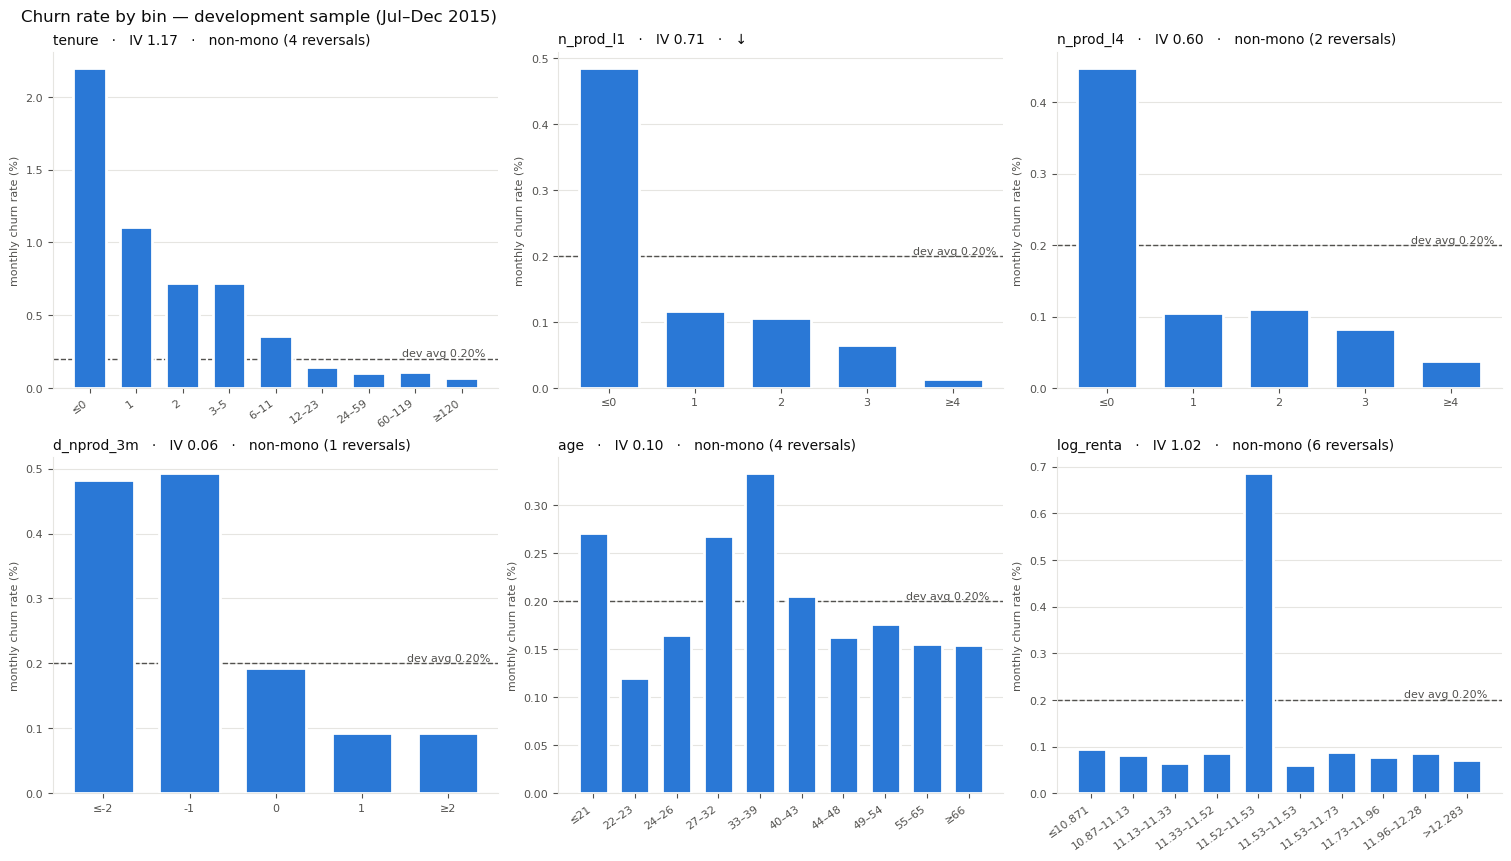

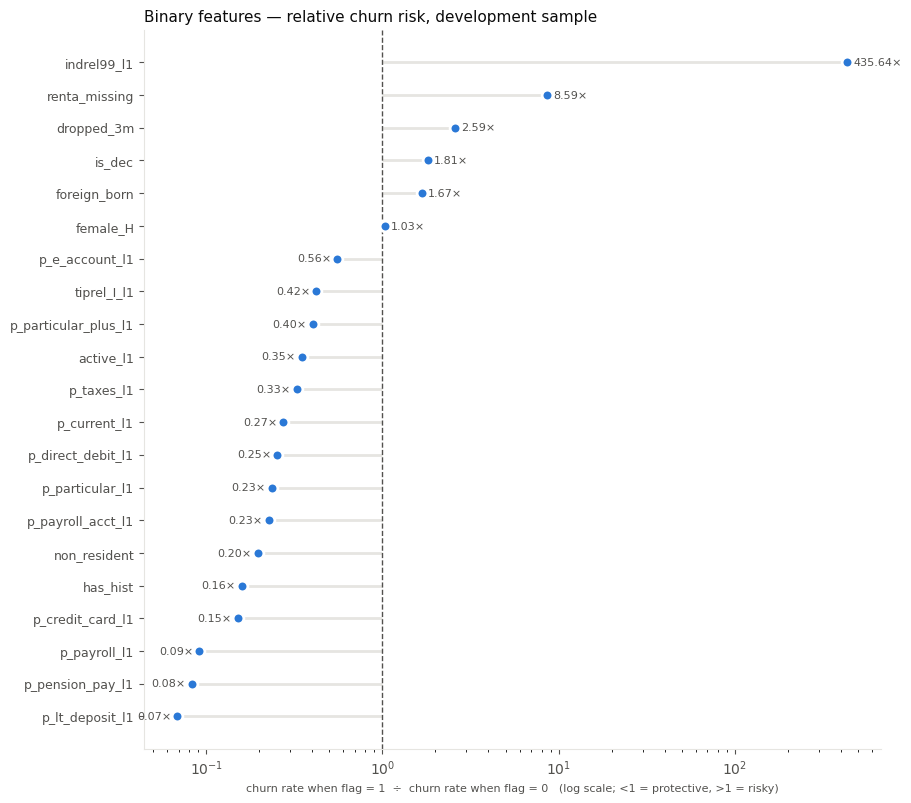

In [29]:
# 6b-3. Monotonicity plots (dev only): monthly churn rate by bin, ordered features
import matplotlib.pyplot as plt

BLUE, INK, MUTED, GRID = "#2a78d6", "#0b0b0b", "#52514e", "#e6e5e1"
base_rate = 100 * dev["churn"].mean()

INTEGER_FEATS = {"tenure", "n_prod_l1", "n_prod_l4", "d_nprod_3m", "age"}

def label_bin(iv, integer=True):
    """(l, r] intervals as readable labels; for integer features (2, 5] means 3–5."""
    if not hasattr(iv, "left"):
        return str(iv)
    l, r = iv.left, iv.right
    if np.isinf(l):  return f"≤{r:g}"
    if np.isinf(r):  return f"≥{l + 1:g}" if integer else f">{l:g}"
    if not integer:  return f"{l:.2f}–{r:.2f}"
    return f"{r:g}" if r - l == 1 else f"{l + 1:g}–{r:g}"

ORDERED = ["tenure", "n_prod_l1", "n_prod_l4", "d_nprod_3m", "age", "log_renta"]
fig, axes = plt.subplots(2, 3, figsize=(15, 8.5), constrained_layout=True)
for ax, f in zip(axes.ravel(), ORDERED):
    tb = BIN_TABLES[f]
    labels = [label_bin(i, integer=f in INTEGER_FEATS) for i in tb.index]
    x = np.arange(len(tb))
    ax.bar(x, tb["rate_%"], width=0.7, color=BLUE, edgecolor="white", linewidth=2, zorder=3)
    ax.axhline(base_rate, color=MUTED, lw=1, ls="--", zorder=2)
    ax.text(len(tb) - 0.5, base_rate, f"dev avg {base_rate:.2f}%", ha="right", va="bottom", fontsize=8, color=MUTED)
    ax.set_xticks(x, labels, rotation=35 if len(tb) > 6 else 0, ha="right" if len(tb) > 6 else "center", fontsize=8)
    ax.set_title(f"{f}   ·   IV {fa.loc[f, 'IV']:.2f}   ·   {fa.loc[f, 'shape']}", fontsize=10, color=INK, loc="left")
    ax.set_ylabel("monthly churn rate (%)", fontsize=8, color=MUTED)
    ax.grid(axis="y", color=GRID, lw=0.8, zorder=0); ax.set_axisbelow(True)
    for s in ["top", "right"]: ax.spines[s].set_visible(False)
    for s in ["left", "bottom"]: ax.spines[s].set_color(GRID)
    ax.tick_params(colors=MUTED, labelsize=8)
fig.suptitle("Churn rate by bin — development sample (Jul–Dec 2015)", fontsize=12, color=INK, x=0.01, ha="left")
plt.show()

# Binary flags: churn rate when the flag is 1 relative to when it is 0 (ratio, log scale)
BIN_FEATS = [f for f in fa.index if fa.loc[f, "bins"] == 2 and f not in ORDERED]
ratio = {}
for f in BIN_FEATS:
    tb = BIN_TABLES[f]
    r = tb["rate_%"]; r.index = [str(i).replace(".0", "") for i in r.index]
    ratio[f] = r.get("1") / r.get("0")
ratio = pd.Series(ratio).sort_values()

fig, ax = plt.subplots(figsize=(9, 0.32 * len(ratio) + 1.2), constrained_layout=True)
y = np.arange(len(ratio))
ax.hlines(y, 1, ratio.values, color=GRID, lw=2, zorder=2)
ax.scatter(ratio.values, y, s=60, color=BLUE, edgecolor="white", linewidth=2, zorder=3)
ax.axvline(1, color=MUTED, lw=1, ls="--")
ax.set_xscale("log")
ax.set_yticks(y, ratio.index, fontsize=9)
for yi, v in zip(y, ratio.values):
    ax.text(v * (1.08 if v >= 1 else 0.92), yi, f"{v:.2f}×", va="center", ha="left" if v >= 1 else "right", fontsize=8, color=MUTED)
ax.set_xlabel("churn rate when flag = 1  ÷  churn rate when flag = 0   (log scale; <1 = protective, >1 = risky)", fontsize=8, color=MUTED)
ax.set_title("Binary features — relative churn risk, development sample", fontsize=11, color=INK, loc="left")
for s in ["top", "right"]: ax.spines[s].set_visible(False)
for s in ["left", "bottom"]: ax.spines[s].set_color(GRID)
ax.tick_params(colors=MUTED)
plt.show()

In [30]:
# 6b-4a. Redundancy: correlated feature pairs (dev only)
NUM = [f for f in FEATURES if f not in CATEG + ["month"]]
corr_m = dev[NUM].astype(float).corr()          # not named "C": that would shadow the formula function C(...)
pairs = (corr_m.where(np.triu(np.ones(corr_m.shape, dtype=bool), k=1)).stack()
           .rename("corr").reset_index().rename(columns={"level_0": "feature_a", "level_1": "feature_b"}))
pairs["abs"] = pairs["corr"].abs()
print("Feature pairs with |correlation| >= 0.5:")
display(pairs[pairs["abs"] >= 0.5].sort_values("abs", ascending=False).drop(columns="abs").round(2).reset_index(drop=True))

# segment / channel blanks vs. tenure 0 — are they the same rows?
blank_seg = dev["segment"] == "NA"
print(f"segment = NA rows: {blank_seg.sum():,} | of which tenure 0: {100 * (dev.loc[blank_seg, 'tenure'] == 0).mean():.1f}% "
      f"| tenure-0 rows with segment NA: {100 * blank_seg[dev['tenure'] == 0].mean():.1f}%")

Feature pairs with |correlation| >= 0.5:


,feature_a,feature_b,corr
0,n_prod_l1,n_prod_l4,0.96
1,p_payroll_l1,p_pension_pay_l1,0.95
2,p_pension_pay_l1,p_payroll_acct_l1,0.80
3,p_payroll_l1,p_payroll_acct_l1,0.77
4,active_l1,tiprel_I_l1,-0.69
5,n_prod_l1,p_direct_debit_l1,0.69
6,n_prod_l1,p_pension_pay_l1,0.68
7,n_prod_l1,p_payroll_l1,0.66
8,n_prod_l1,p_payroll_acct_l1,0.66
9,p_direct_debit_l1,n_prod_l4,0.65


segment = NA rows: 11,933 | of which tenure 0: 88.0% | tenure-0 rows with segment NA: 100.0%


In [31]:
# 6b-4b. Tenure interaction: does each feature's effect hold for new AND established customers? (dev only)
# Relative risk = churn rate when the feature is "on" ÷ when "off", computed separately by tenure group.
dev_ = dev.assign(new_cust=dev["tenure"] <= 11, has_hist_on=dev["has_hist"] == 1)
ON = {                                                 # how each feature is switched "on" for the comparison
    "n_prod_l1 = 0":       dev_["n_prod_l1"] == 0,
    "n_prod_l1 >= 3":      dev_["n_prod_l1"] >= 3,
    "dropped_3m":          dev_["dropped_3m"] == 1,
    "active_l1":           dev_["active_l1"] == 1,
    "p_current_l1":        dev_["p_current_l1"] == 1,
    "p_payroll_l1":        dev_["p_payroll_l1"] == 1,
    "p_direct_debit_l1":   dev_["p_direct_debit_l1"] == 1,
    "p_credit_card_l1":    dev_["p_credit_card_l1"] == 1,
    "renta_missing":       dev_["renta_missing"] == 1,
    "foreign_born":        dev_["foreign_born"] == 1,
    "is_dec":              dev_["is_dec"] == 1,
    "age 27-39":           dev_["age"].between(27, 39),
}
rows = []
for name, on in ON.items():
    r = {"feature (on)": name}
    for grp, mask in [("new (tenure ≤ 11)", dev_["new_cust"]), ("established (tenure ≥ 12)", ~dev_["new_cust"])]:
        y = dev_.loc[mask, "churn"].astype(int); o = on[mask]
        r_on, r_off = y[o].mean(), y[~o].mean()
        r[f"{grp}: RR"] = round(r_on / r_off, 2) if r_off > 0 and o.sum() > 0 else np.nan
        r[f"{grp}: rows on"] = int(o.sum())
    rows.append(r)
inter = pd.DataFrame(rows).set_index("feature (on)")
rr_new, rr_est = inter.iloc[:, 0], inter.iloc[:, 2]
inter["same direction"] = np.where(np.sign(np.log(rr_new)) == np.sign(np.log(rr_est)), "yes", "NO")
inter["ratio new/est"] = (rr_new / rr_est).round(2)
inter

C:\Users\Danie\anaconda3\Lib\site-packages\pandas\core\arraylike.py:399: RuntimeWarning: divide by zero encountered in log
  result = getattr(ufunc, method)(*inputs, **kwargs)


,new (tenure ≤ 11): RR,new (tenure ≤ 11): rows on,established (tenure ≥ 12): RR,established (tenure ≥ 12): rows on,same direction,ratio new/est
feature (on),,,,,,
n_prod_l1 = 0,6.50,27834,2.08,109131,yes,3.12
n_prod_l1 >= 3,0.05,2281,0.31,68122,yes,0.16
dropped_3m,1.48,1552,4.98,16583,yes,0.30
active_l1,0.23,26535,0.63,193285,yes,0.37
p_current_l1,0.17,40768,0.53,273391,yes,0.32
p_payroll_l1,0.07,1626,0.16,24513,yes,0.44
p_direct_debit_l1,0.09,3961,0.52,55550,yes,0.17
p_credit_card_l1,0.00,316,0.32,22001,yes,0.00
renta_missing,5.78,26369,6.01,75487,yes,0.96


## Step 7: Model

### 7a. Which tenure baseline? (dev only)

Baseline-only models `churn ~ <tenure spec>`, compared on **5-fold out-of-sample log loss with folds grouped by customer** (a customer is never in train and test at once), plus AIC/BIC. Candidates follow Singer & Willett's menu (constant, polynomial, completely general/bands) plus natural cubic splines on tenure and on log(tenure + 1).

In [39]:
# 7a-1. Fit and score candidate tenure baselines
import statsmodels.formula.api as smf
from sklearn.model_selection import GroupKFold
import warnings; warnings.filterwarnings("ignore")

d = dev[["ncodpers", "churn", "tenure"]].copy()
d["churn"] = d["churn"].astype(int)
d["tenure"] = d["tenure"].astype(float)
d["log_ten"] = np.log1p(d["tenure"])
d["ten_band"] = pd.cut(d["tenure"], CUSTOM_EDGES["tenure"]).astype(str)     # life-table bands: 0,1,2,3-5,6-11,12-23,24-59,60-119,120+

SPECS = {
    "constant (no tenure)":       "churn ~ 1",
    "linear tenure":              "churn ~ tenure",
    "cubic polynomial":           "churn ~ tenure + I(tenure**2) + I(tenure**3)",
    "log(tenure+1)":              "churn ~ log_ten",
    "tenure bands (9 dummies)":   "churn ~ C(ten_band)",
    "spline tenure df=3":         "churn ~ cr(tenure, df=3)",
    "spline tenure df=5":         "churn ~ cr(tenure, df=5)",
    "spline tenure df=8":         "churn ~ cr(tenure, df=8)",
    "spline log-tenure df=3":     "churn ~ cr(log_ten, df=3)",
    "spline log-tenure df=4":     "churn ~ cr(log_ten, df=4)",
    "spline log-tenure df=5":     "churn ~ cr(log_ten, df=5)",
    "spline log-tenure df=6":     "churn ~ cr(log_ten, df=6)",
    "spline log-tenure df=8":     "churn ~ cr(log_ten, df=8)",
}

def logloss(y, p):
    p = np.clip(p, 1e-9, 1 - 1e-9)
    return -np.mean(y * np.log(p) + (1 - y) * np.log(1 - p))

gkf = GroupKFold(n_splits=5)
folds = list(gkf.split(d, groups=d["ncodpers"]))
FITS = globals().get("FITS", {})                 # resumable: keeps results already computed in this session
BASE_ROWS = globals().get("BASE_ROWS", [])
done = {r["baseline"] for r in BASE_ROWS}
for name, f in SPECS.items():
    if name in done:
        continue
    full = smf.logit(f, data=d).fit(disp=0, maxiter=200)
    FITS[name] = full
    cv = []
    for tr, te in folds:
        m = smf.logit(f, data=d.iloc[tr]).fit(disp=0, maxiter=200)
        cv.append(logloss(d["churn"].iloc[te].to_numpy(), m.predict(d.iloc[te]).to_numpy()))
    BASE_ROWS.append({"baseline": name, "params": int(full.df_model) + 1,
                      "CV log loss x1000": round(1000 * np.mean(cv), 4),
                      "AIC": round(full.aic, 1), "BIC": round(full.bic, 1)})

cmp_ = pd.DataFrame(BASE_ROWS).set_index("baseline")
best = cmp_["CV log loss x1000"].min()
cmp_["vs best (CV)"] = (cmp_["CV log loss x1000"] - best).round(4)
cmp_.sort_values("CV log loss x1000")

,params,CV log loss x1000,AIC,BIC,vs best (CV)
baseline,,,,,
tenure bands (9 dummies),9,13.0866,13736.4,13836.9,0.0000
spline log-tenure df=8,9,13.0899,13742.8,13843.3,0.0033
spline log-tenure df=3,4,13.0925,13742.3,13787.0,0.0059
spline log-tenure df=4,5,13.0932,13743.6,13799.5,0.0066
spline log-tenure df=5,6,13.0941,13745.5,13812.5,0.0075
spline log-tenure df=6,7,13.0963,13747.5,13825.7,0.0097
log(tenure+1),2,13.1416,13790.3,13812.6,0.0550
spline tenure df=8,9,13.1671,13819.3,13919.9,0.0805
cubic polynomial,4,13.3089,13961.8,14006.5,0.2223


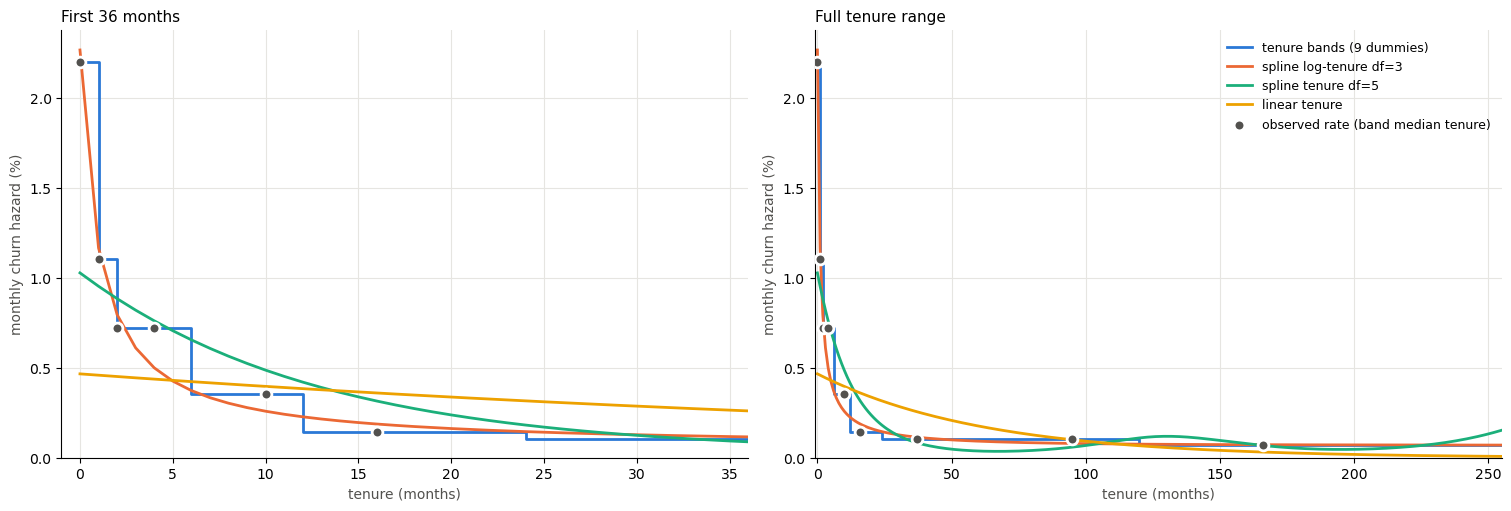

In [40]:
# 7a-2. What the candidate baselines look like vs. the observed life table (dev)
grid = pd.DataFrame({"tenure": np.arange(0, 256, dtype=float)})
grid["log_ten"] = np.log1p(grid["tenure"])
grid["ten_band"] = pd.cut(grid["tenure"], CUSTOM_EDGES["tenure"]).astype(str)

obs = d.groupby("ten_band")["churn"].agg(["mean", "size"])
band_mid = d.groupby("ten_band")["tenure"].median()

SHOW = {"tenure bands (9 dummies)": "#2a78d6", "spline log-tenure df=3": "#eb6834",
        "spline tenure df=5": "#1baf7a", "linear tenure": "#eda100"}
fig, axes = plt.subplots(1, 2, figsize=(15, 5), constrained_layout=True)
for ax, xmax in zip(axes, [36, 255]):
    for name, col in SHOW.items():
        ax.plot(grid["tenure"], 100 * FITS[name].predict(grid), color=col, lw=2,
                drawstyle="steps-post" if "bands" in name else "default", label=name)
    ax.scatter(band_mid, 100 * obs["mean"], s=60, color="#52514e", edgecolor="white", linewidth=2,
               zorder=5, label="observed rate (band median tenure)")
    ax.set_xlim(-1, xmax); ax.set_ylim(0, None)
    ax.set_xlabel("tenure (months)", color=MUTED); ax.set_ylabel("monthly churn hazard (%)", color=MUTED)
    ax.set_title(f"First {xmax} months" if xmax < 100 else "Full tenure range", loc="left", fontsize=11)
    ax.grid(color=GRID, lw=0.8); ax.set_axisbelow(True)
    for s in ["top", "right"]: ax.spines[s].set_visible(False)
axes[1].legend(frameon=False, fontsize=9)
plt.show()

### 7b. Model-ready columns (same transform applied to dev and OOT)

| Column | Built from | Why (step 6b) |
|---|---|---|
| `log_ten` | log(tenure + 1) | Baseline: spline on log-tenure won 7a |
| `new_cust` | tenure ≤ 11 | What the interactions are with |
| `n_prod_c` | n_prod_l1 capped at 4 | 0 / 1 / 2 / 3 / 4+ levels (0→1 is the big step) |
| `prod_trend` | d_nprod_3m | dropped / no_change / added |
| `p_payroll_any_l1` | payroll OR pension pay OR payroll account | The three were 0.77–0.95 correlated |
| `age_band` | age | Hump-shaped: ≤23, 24–26, 27–39, 40–54, 55+ |
| `segment_m` | segment, NA → 02 | NA was a proxy for tenure 0 |

In [43]:
# 7b. Build model-ready frames
def prep(D):
    D = D.copy()
    D["churn"] = D["churn"].astype(int)
    D["tenure"] = D["tenure"].astype(float)
    D["log_ten"] = np.log1p(D["tenure"])
    D["new_cust"] = (D["tenure"] <= 11).astype(int)
    D["n_prod_c"] = D["n_prod_l1"].clip(upper=4).astype(int).astype(str).replace({"4": "4+"})
    D["prod_trend"] = np.select([D["d_nprod_3m"] < 0, D["d_nprod_3m"] > 0], ["dropped", "added"], "no_change")
    D["p_payroll_any_l1"] = ((D["p_payroll_l1"] + D["p_pension_pay_l1"] + D["p_payroll_acct_l1"]) > 0).astype(int)
    D["age_band"] = pd.cut(D["age"].astype(float), [-1, 23, 26, 39, 54, 200],
                           labels=["<=23", "24-26", "27-39", "40-54", "55+"]).astype(str)
    D["segment_m"] = D["segment"].astype(str).replace({"NA": "02"})
    for c in ["n_prod_c", "prod_trend", "age_band", "segment_m", "channel"]:      # plain object dtype: patsy can't read pandas "string"
        D[c] = D[c].astype(str).astype(object)
    for c in ["active_l1", "p_current_l1", "p_direct_debit_l1", "p_credit_card_l1", "p_lt_deposit_l1", "indrel99_l1",
              "renta_missing", "foreign_born", "has_hist", "is_dec"]:
        D[c] = D[c].astype(int)
    return D

mdev, moot = prep(dev), prep(oot)
print("dev:", mdev.shape, "| oot:", moot.shape)
for c in ["n_prod_c", "prod_trend", "age_band", "segment_m", "channel"]:
    print(f"{c:11s}", mdev[c].value_counts().sort_index().to_dict())

dev: (524598, 42) | oot: (368892, 42)
n_prod_c    {'0': 136965, '1': 250683, '2': 66547, '3': 27354, '4+': 43049}
prod_trend  {'added': 19297, 'dropped': 18135, 'no_change': 487166}
age_band    {'24-26': 57047, '27-39': 101564, '40-54': 154471, '55+': 100731, '<=23': 110785}
segment_m   {'01': 19680, '02': 321446, '03': 183472}
channel     {'KAT': 124574, 'KFA': 15318, 'KFC': 121303, 'KHE': 152444, 'KHQ': 21722, 'other': 89237}


In [45]:
# 7c. Full discrete-time hazard logit on dev
FORMULA = (
    "churn ~ cr(log_ten, df=3, constraints='center')"             # baseline alpha(tenure); centered so it doesn't duplicate the Intercept
    " + C(n_prod_c, Treatment('1'))"                              # ref: 1 product
    " + C(prod_trend, Treatment('no_change'))"
    " + renta_missing + foreign_born + has_hist + indrel99_l1"
    " + C(age_band, Treatment('40-54'))"
    " + C(segment_m, Treatment('02')) + C(channel, Treatment('KHE'))"
    " + p_payroll_any_l1 + p_credit_card_l1 + p_lt_deposit_l1"
    " + active_l1 * new_cust + p_current_l1 * new_cust + p_direct_debit_l1 * new_cust"
    " + is_dec * new_cust"
)
full = smf.logit(FORMULA, data=mdev).fit(disp=0, maxiter=300)

ci = full.conf_int()
coef = pd.DataFrame({"coef": full.params, "OR": np.exp(full.params),
                     "OR_lo95": np.exp(ci[0]), "OR_hi95": np.exp(ci[1]), "p": full.pvalues})
coef = coef[~coef.index.str.startswith("cr(")]                    # spline terms: read as a curve, not coefficients
print(f"n = {int(full.nobs):,} | events = {int(mdev['churn'].sum()):,} | params = {int(full.df_model) + 1} "
      f"| pseudo-R² = {full.prsquared:.3f} | AIC = {full.aic:,.1f} (baseline-only AIC = {FITS['spline log-tenure df=3'].aic:,.1f})")
coef.round({"coef": 3, "OR": 3, "OR_lo95": 3, "OR_hi95": 3, "p": 4})

n = 524,598 | events = 1,050 | params = 37 | pseudo-R² = 0.237 | AIC = 11,631.4 (baseline-only AIC = 13,742.3)


,coef,OR,OR_lo95,OR_hi95,p
Intercept,-7.646,0.000,0.000,0.001,0.0000
"C(n_prod_c, Treatment('1'))[T.0]",0.419,1.520,1.098,2.105,0.0117
"C(n_prod_c, Treatment('1'))[T.2]",0.215,1.239,0.878,1.749,0.2227
"C(n_prod_c, Treatment('1'))[T.3]",-0.178,0.837,0.458,1.530,0.5635
"C(n_prod_c, Treatment('1'))[T.4+]",-1.097,0.334,0.119,0.939,0.0377
"C(prod_trend, Treatment('no_change'))[T.added]",0.612,1.845,1.085,3.138,0.0238
"C(prod_trend, Treatment('no_change'))[T.dropped]",1.344,3.834,2.952,4.979,0.0000
"C(age_band, Treatment('40-54'))[T.24-26]",-0.607,0.545,0.408,0.728,0.0000
"C(age_band, Treatment('40-54'))[T.27-39]",-0.206,0.814,0.677,0.978,0.0283
"C(age_band, Treatment('40-54'))[T.55+]",-0.052,0.949,0.771,1.169,0.6246


## Step 8: Out-of-time evaluation (Jan–Apr 2016)

First and only use of OOT outcomes. Metrics on customer-month rows:

| Metric | Answers |
|---|---|
| AUC | Ranking: does a churner score above a non-churner? (0.5 = random) |
| PR-AUC | Ranking under rare events; compare with the base rate (~0.2%) |
| Log loss | Probability accuracy (lower = better) |
| Calibration | Predicted vs observed churn, overall and by decile |
| Top-decile capture / lift | Share of churners in the riskiest 10% of rows — what a retention list would catch |

In [46]:
# 8a. Score dev and OOT; headline metrics vs. the tenure-only baseline
from sklearn.metrics import roc_auc_score, average_precision_score

def evaluate(y, p, label):
    y, p = np.asarray(y), np.asarray(p)
    top = p >= np.quantile(p, 0.9)
    return {"model / sample": label, "rows": len(y), "events": int(y.sum()),
            "AUC": round(roc_auc_score(y, p), 4), "PR-AUC": round(average_precision_score(y, p), 4),
            "log loss x1000": round(1000 * logloss(y, p), 3),
            "pred events": round(p.sum(), 1), "pred/obs": round(p.sum() / y.sum(), 3),
            "top-10% capture %": round(100 * y[top].sum() / y.sum(), 1),
            "top-10% lift": round((y[top].mean()) / y.mean(), 2)}

base = FITS["spline log-tenure df=3"]
mdev["p_full"], moot["p_full"] = full.predict(mdev), full.predict(moot)
mdev["p_base"], moot["p_base"] = base.predict(mdev), base.predict(moot)

ev = pd.DataFrame([
    evaluate(mdev["churn"], mdev["p_base"], "tenure-only  · dev"),
    evaluate(mdev["churn"], mdev["p_full"], "full model   · dev"),
    evaluate(moot["churn"], moot["p_base"], "tenure-only  · OOT"),
    evaluate(moot["churn"], moot["p_full"], "full model   · OOT"),
]).set_index("model / sample")
ev

,rows,events,AUC,PR-AUC,log loss x1000,pred events,pred/obs,top-10% capture %,top-10% lift
model / sample,,,,,,,,,
tenure-only · dev,524598,1050,0.7619,0.0112,13.090,1050.0,1.000,55.8,5.06
full model · dev,524598,1050,0.8679,0.1092,11.015,1050.0,1.000,69.6,6.96
tenure-only · OOT,368892,750,0.7308,0.0284,13.105,605.2,0.807,48.5,4.31
full model · OOT,368892,750,0.8008,0.0331,12.525,693.6,0.925,58.0,5.80


In [47]:
# 8b. How much of the dev-vs-OOT gap is the indrel99_l1 flag? Refit without it and compare.
for nm, D in [("dev", mdev), ("OOT", moot)]:
    f_ = D["indrel99_l1"] == 1
    print(f"{nm}: indrel99_l1 rows = {int(f_.sum())}, events among them = {int(D.loc[f_, 'churn'].sum())} "
          f"({100 * D.loc[f_, 'churn'].sum() / D['churn'].sum():.1f}% of all {nm} events)")

FORMULA_NO_IND = FORMULA.replace(" + indrel99_l1", "")
full_noind = smf.logit(FORMULA_NO_IND, data=mdev).fit(disp=0, maxiter=300)
mdev["p_noind"], moot["p_noind"] = full_noind.predict(mdev), full_noind.predict(moot)

ev2 = pd.DataFrame([
    evaluate(mdev["churn"], mdev["p_noind"], "full w/o indrel99 · dev"),
    evaluate(moot["churn"], moot["p_noind"], "full w/o indrel99 · OOT"),
]).set_index("model / sample")
pd.concat([ev, ev2])

dev: indrel99_l1 rows = 86, events among them = 70 (6.7% of all dev events)
OOT: indrel99_l1 rows = 12, events among them = 2 (0.3% of all OOT events)


,rows,events,AUC,PR-AUC,log loss x1000,pred events,pred/obs,top-10% capture %,top-10% lift
model / sample,,,,,,,,,
tenure-only · dev,524598,1050,0.7619,0.0112,13.090,1050.0,1.000,55.8,5.06
full model · dev,524598,1050,0.8679,0.1092,11.015,1050.0,1.000,69.6,6.96
tenure-only · OOT,368892,750,0.7308,0.0284,13.105,605.2,0.807,48.5,4.31
full model · OOT,368892,750,0.8008,0.0331,12.525,693.6,0.925,58.0,5.80
full w/o indrel99 · dev,524598,1050,0.8598,0.0410,11.624,1050.0,1.000,66.6,6.66
full w/o indrel99 · OOT,368892,750,0.7983,0.0278,12.528,769.4,1.026,57.6,5.76


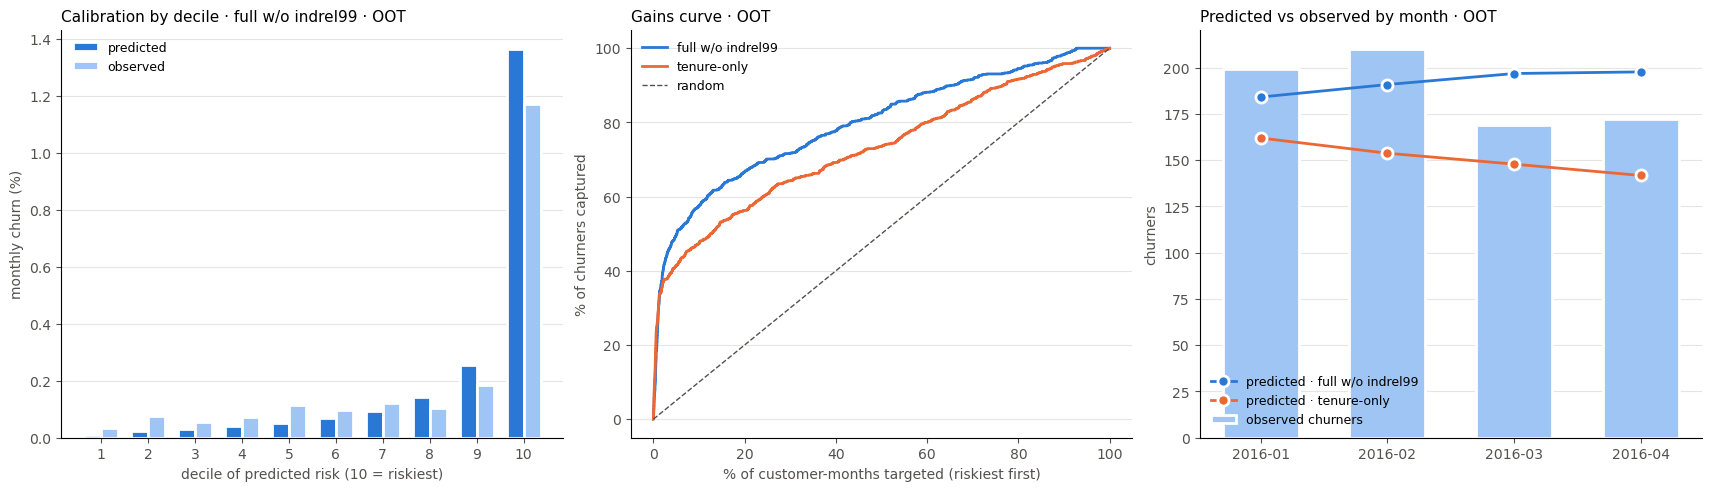

p_noind,1,2,3,4,5,6,7,8,9,10
pred_pct,0.009,0.024,0.032,0.041,0.053,0.069,0.094,0.144,0.255,1.366
obs_pct,0.035,0.076,0.057,0.073,0.114,0.098,0.122,0.103,0.184,1.171


fecha_dato,2016-01,2016-02,2016-03,2016-04
obs,199.0,210.0,169.0,172.0
pred,184.1,190.8,196.8,197.7
base,162.0,153.7,147.8,141.7


In [48]:
# 8c. OOT calibration by decile, gains (capture) curve, and predicted vs observed by month
fig, axes = plt.subplots(1, 3, figsize=(17, 4.8), constrained_layout=True)
MODELS = {"full w/o indrel99": ("p_noind", "#2a78d6"), "tenure-only": ("p_base", "#eb6834")}

# (1) calibration: mean predicted vs observed churn by decile of predicted risk (full w/o indrel99)
dec = pd.qcut(moot["p_noind"].rank(method="first"), 10, labels=False) + 1
cal = moot.groupby(dec).agg(pred=("p_noind", "mean"), obs=("churn", "mean"))
ax = axes[0]
x = np.arange(1, 11)
ax.bar(x - 0.18, 100 * cal["pred"], width=0.36, color="#2a78d6", edgecolor="white", lw=2, label="predicted")
ax.bar(x + 0.18, 100 * cal["obs"], width=0.36, color="#9ec5f4", edgecolor="white", lw=2, label="observed")
ax.set_xticks(x); ax.set_xlabel("decile of predicted risk (10 = riskiest)", color=MUTED)
ax.set_ylabel("monthly churn (%)", color=MUTED); ax.set_title("Calibration by decile · full w/o indrel99 · OOT", loc="left", fontsize=11)
ax.legend(frameon=False, fontsize=9)

# (2) gains curve: share of OOT churners captured when targeting the top x% of rows
ax = axes[1]
for name, (col, c) in MODELS.items():
    o = moot.sort_values(col, ascending=False)
    cum = o["churn"].cumsum().to_numpy() / o["churn"].sum()
    frac = np.arange(1, len(o) + 1) / len(o)
    ax.plot(100 * frac, 100 * cum, color=c, lw=2, label=name)
ax.plot([0, 100], [0, 100], color=MUTED, lw=1, ls="--", label="random")
ax.set_xlabel("% of customer-months targeted (riskiest first)", color=MUTED); ax.set_ylabel("% of churners captured", color=MUTED)
ax.set_title("Gains curve · OOT", loc="left", fontsize=11); ax.legend(frameon=False, fontsize=9)

# (3) predicted vs observed churners by OOT month
ax = axes[2]
mon = moot.groupby(moot["fecha_dato"].dt.strftime("%Y-%m")).agg(obs=("churn", "sum"), pred=("p_noind", "sum"), base=("p_base", "sum"))
xm = np.arange(len(mon))
ax.bar(xm, mon["obs"], width=0.6, color="#9ec5f4", edgecolor="white", lw=2, label="observed churners")
ax.plot(xm, mon["pred"], color="#2a78d6", lw=2, marker="o", ms=8, mec="white", mew=2, label="predicted · full w/o indrel99")
ax.plot(xm, mon["base"], color="#eb6834", lw=2, marker="o", ms=8, mec="white", mew=2, label="predicted · tenure-only")
ax.set_xticks(xm, mon.index); ax.set_ylabel("churners", color=MUTED)
ax.set_title("Predicted vs observed by month · OOT", loc="left", fontsize=11); ax.legend(frameon=False, fontsize=9)

for ax in axes:
    ax.grid(axis="y", color=GRID, lw=0.8); ax.set_axisbelow(True)
    for s in ["top", "right"]: ax.spines[s].set_visible(False)
    ax.tick_params(colors=MUTED)
plt.show()
display(cal.assign(pred_pct=lambda t: (100 * t.pred).round(3), obs_pct=lambda t: (100 * t.obs).round(3))[["pred_pct", "obs_pct"]].T)
display(mon.round(1).T)

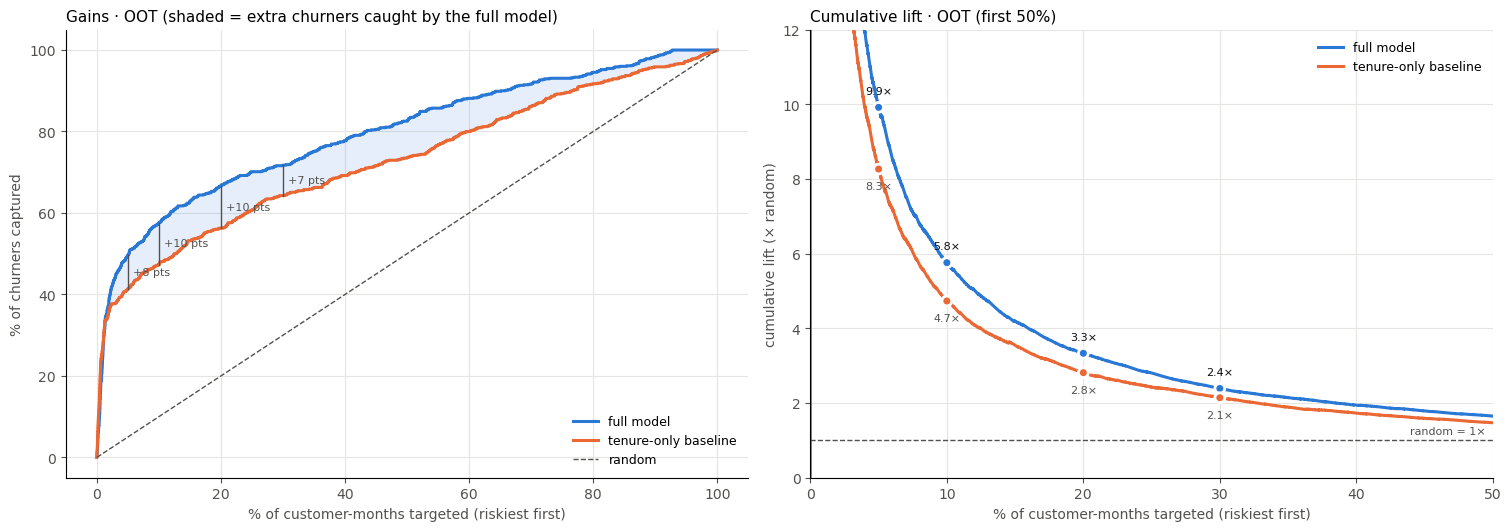

,top 5%,top 10%,top 20%,top 30%
capture · full,49.6%,57.6%,66.7%,71.7%
capture · baseline,41.3%,47.3%,56.3%,64.3%
lift · full,9.92×,5.76×,3.33×,2.39×
lift · baseline,8.27×,4.73×,2.81×,2.14×


In [49]:
# 8d. Gains and cumulative lift: full model (w/o indrel99) vs tenure-only baseline, OOT
def gains(col):
    o = moot.sort_values(col, ascending=False)
    frac = np.arange(1, len(o) + 1) / len(o)
    cap = o["churn"].cumsum().to_numpy() / o["churn"].sum()
    return frac, cap

fF, cF = gains("p_noind"); fB, cB = gains("p_base")
FULL_C, BASE_C = "#2a78d6", "#eb6834"
marks = [0.05, 0.10, 0.20, 0.30]

fig, axes = plt.subplots(1, 2, figsize=(15, 5.2), constrained_layout=True)

# (1) gains with the gap shaded
ax = axes[0]
ax.plot(100 * fF, 100 * cF, color=FULL_C, lw=2.2, label="full model")
ax.plot(100 * fB, 100 * cB, color=BASE_C, lw=2.2, label="tenure-only baseline")
ax.fill_between(100 * fF, 100 * np.interp(fF, fB, cB), 100 * cF, color=FULL_C, alpha=0.12, lw=0)
ax.plot([0, 100], [0, 100], color=MUTED, lw=1, ls="--", label="random")
for m in marks:
    yF, yB = 100 * np.interp(m, fF, cF), 100 * np.interp(m, fB, cB)
    ax.plot([100 * m] * 2, [yB, yF], color=MUTED, lw=1)
    ax.text(100 * m + 0.8, (yF + yB) / 2, f"+{yF - yB:.0f} pts", fontsize=8, color=MUTED, va="center")
ax.set_xlabel("% of customer-months targeted (riskiest first)", color=MUTED)
ax.set_ylabel("% of churners captured", color=MUTED)
ax.set_title("Gains · OOT (shaded = extra churners caught by the full model)", loc="left", fontsize=11)
ax.legend(frameon=False, fontsize=9, loc="lower right")

# (2) cumulative lift = capture% / targeted%
ax = axes[1]
keep = fF <= 0.5
ax.plot(100 * fF[keep], (cF / fF)[keep], color=FULL_C, lw=2.2, label="full model")
keepB = fB <= 0.5
ax.plot(100 * fB[keepB], (cB / fB)[keepB], color=BASE_C, lw=2.2, label="tenure-only baseline")
ax.axhline(1, color=MUTED, lw=1, ls="--")
ax.text(49.5, 1.15, "random = 1×", ha="right", fontsize=8, color=MUTED)
for m in marks:
    lF, lB = np.interp(m, fF, cF) / m, np.interp(m, fB, cB) / m
    ax.scatter([100 * m] * 2, [lF, lB], s=50, color=[FULL_C, BASE_C], edgecolor="white", linewidth=2, zorder=5)
    ax.text(100 * m, lF + 0.35, f"{lF:.1f}×", ha="center", fontsize=8, color=INK)
    ax.text(100 * m, lB - 0.55, f"{lB:.1f}×", ha="center", fontsize=8, color=MUTED)
ax.set_xlim(0, 50); ax.set_ylim(0, 12)
ax.set_xlabel("% of customer-months targeted (riskiest first)", color=MUTED)
ax.set_ylabel("cumulative lift (× random)", color=MUTED)
ax.set_title("Cumulative lift · OOT (first 50%)", loc="left", fontsize=11)
ax.legend(frameon=False, fontsize=9)

for ax in axes:
    ax.grid(color=GRID, lw=0.8); ax.set_axisbelow(True)
    for s in ["top", "right"]: ax.spines[s].set_visible(False)
    ax.tick_params(colors=MUTED)
plt.show()

tbl = pd.DataFrame({f"top {int(100*m)}%": {
    "capture · full": f"{100*np.interp(m, fF, cF):.1f}%", "capture · baseline": f"{100*np.interp(m, fB, cB):.1f}%",
    "lift · full": f"{np.interp(m, fF, cF)/m:.2f}×", "lift · baseline": f"{np.interp(m, fB, cB)/m:.2f}×"} for m in marks})
tbl

## Step 9: Prune + regularize

Goal: fix the overconfidence seen in 8c (top decile over-predicted, deciles 1–7 under-predicted) by cutting parameters and shrinking coefficients.

| Change | Detail |
|---|---|
| Dropped | `indrel99_l1` (didn't generalize, 8b), `foreign_born` (p 0.59), `p_credit_card_l1` (p 0.42), `has_hist` (p 0.07) |
| Collapsed | segment 01 → 02 (only 03 differs: `seg_univ` flag); channels KFC, KHQ → KHE (not different from it) |
| L2 penalty | sklearn `LogisticRegression`, strength `C` tuned on **dev** by 5-fold customer-grouped log loss; OOT untouched until the final comparison |

In [50]:
# 9a. Pruned formula (unpenalized) — compare fit with the full model
for D in (mdev, moot):
    D["seg_univ"] = (D["segment_m"] == "03").astype(int)
    D["channel_p"] = D["channel"].replace({"KFC": "KHE", "KHQ": "KHE"}).astype(object)

PRUNED_RHS = (
    "cr(log_ten, df=3, constraints='center')"
    " + C(n_prod_c, Treatment('1')) + C(prod_trend, Treatment('no_change'))"
    " + renta_missing + C(age_band, Treatment('40-54')) + seg_univ + C(channel_p, Treatment('KHE'))"
    " + p_payroll_any_l1 + p_lt_deposit_l1"
    " + active_l1 * new_cust + p_current_l1 * new_cust + p_direct_debit_l1 * new_cust + is_dec * new_cust"
)
pruned = smf.logit("churn ~ " + PRUNED_RHS, data=mdev).fit(disp=0, maxiter=300)
mdev["p_pruned"], moot["p_pruned"] = pruned.predict(mdev), pruned.predict(moot)

print(pd.DataFrame({
    "params": {"full w/o indrel99": int(full_noind.df_model) + 1, "pruned": int(pruned.df_model) + 1},
    "AIC":    {"full w/o indrel99": round(full_noind.aic, 1), "pruned": round(pruned.aic, 1)},
    "BIC":    {"full w/o indrel99": round(full_noind.bic, 1), "pruned": round(pruned.bic, 1)},
}))

                   params      AIC      BIC
full w/o indrel99      36  12267.9  12670.0
pruned                 30  12269.9  12605.0


In [51]:
# 9b. L2 (ridge) penalty strength tuned on dev with customer-grouped CV
from patsy import dmatrix, build_design_matrices
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler

Xd_df = dmatrix(PRUNED_RHS, mdev, return_type="dataframe")
DINFO = Xd_df.design_info
Xd_df = Xd_df.drop(columns="Intercept")                                   # sklearn fits its own (unpenalized) intercept
Xo_df = build_design_matrices([DINFO], moot, return_type="dataframe")[0].drop(columns="Intercept")
yd, yo = mdev["churn"].to_numpy(), moot["churn"].to_numpy()

scaler = StandardScaler().fit(Xd_df)                                       # put columns on one scale so the penalty is fair
Xd, Xo = scaler.transform(Xd_df), scaler.transform(Xo_df)

C_GRID = [0.001, 0.003, 0.01, 0.03, 0.1, 0.3, 1.0, 1e4]                   # small C = strong shrinkage; 1e4 ≈ unpenalized
folds9 = list(GroupKFold(n_splits=5).split(Xd, groups=mdev["ncodpers"]))
cv_rows = []
for Cval in C_GRID:
    ll = []
    for tr, te in folds9:
        m = LogisticRegression(C=Cval, max_iter=2000).fit(Xd[tr], yd[tr])
        ll.append(logloss(yd[te], m.predict_proba(Xd[te])[:, 1]))
    cv_rows.append({"C": Cval, "CV log loss x1000": 1000 * np.mean(ll), "se x1000": 1000 * np.std(ll) / np.sqrt(len(ll))})
cvC = pd.DataFrame(cv_rows).set_index("C")
best_C = cvC["CV log loss x1000"].idxmin()
# 1-SE rule: strongest penalty whose CV loss is within one standard error of the best
thr = cvC.loc[best_C, "CV log loss x1000"] + cvC.loc[best_C, "se x1000"]
C_1se = min(c for c in cvC.index if cvC.loc[c, "CV log loss x1000"] <= thr)
print(f"best C = {best_C} | 1-SE C = {C_1se}")
cvC.round(4)

best C = 0.03 | 1-SE C = 0.003


,CV log loss x1000,se x1000
C,,
0.001,11.9762,0.1724
0.003,11.7842,0.1749
0.010,11.7192,0.1793
0.030,11.7108,0.1807
0.100,11.7139,0.1836
0.300,11.7144,0.1840
1.000,11.7147,0.1841
10000.000,11.7148,0.1842


In [52]:
# 9c. Fit the penalized models on all of dev, then the one-time OOT comparison
for Cval, tag in [(best_C, "p_l2_best"), (C_1se, "p_l2_1se")]:
    m = LogisticRegression(C=Cval, max_iter=2000).fit(Xd, yd)
    mdev[tag], moot[tag] = m.predict_proba(Xd)[:, 1], m.predict_proba(Xo)[:, 1]

CANDS = {"full w/o indrel99 (36 params)": "p_noind", "pruned (30)": "p_pruned",
         f"pruned + L2, C={best_C} (CV-best)": "p_l2_best", f"pruned + L2, C={C_1se} (1-SE)": "p_l2_1se"}
ev9 = pd.DataFrame([evaluate(moot["churn"], moot[c], n) for n, c in CANDS.items()]).set_index("model / sample")

def decile_cal(col):
    dec_ = pd.qcut(moot[col].rank(method="first"), 10, labels=False) + 1
    g = moot.groupby(dec_).agg(pred=(col, "mean"), obs=("churn", "mean"))
    return g

cal_err = {}
for n, c in CANDS.items():
    g = decile_cal(c)
    cal_err[n] = {"mean |pred-obs| per decile (pp)": round(100 * (g["pred"] - g["obs"]).abs().mean(), 4),
                  "top decile pred/obs": round(g["pred"].iloc[-1] / g["obs"].iloc[-1], 2),
                  "deciles 1-7 pred/obs": round(g["pred"].iloc[:7].sum() / g["obs"].iloc[:7].sum(), 2)}
display(ev9.drop(columns=["rows", "events"]))
display(pd.DataFrame(cal_err).T)

,AUC,PR-AUC,log loss x1000,pred events,pred/obs,top-10% capture %,top-10% lift
model / sample,,,,,,,
full w/o indrel99 (36 params),0.7983,0.0278,12.528,769.4,1.026,57.6,5.76
pruned (30),0.7999,0.0325,12.529,772.9,1.031,58.1,5.81
"pruned + L2, C=0.03 (CV-best)",0.7986,0.0308,12.544,747.4,0.997,57.3,5.73
"pruned + L2, C=0.003 (1-SE)",0.8001,0.0304,12.471,705.3,0.940,57.7,5.77


,mean |pred-obs| per decile (pp),top decile pred/obs,deciles 1-7 pred/obs
full w/o indrel99 (36 params),0.0558,1.17,0.56
pruned (30),0.0552,1.16,0.57
"pruned + L2, C=0.03 (CV-best)",0.0443,1.12,0.59
"pruned + L2, C=0.003 (1-SE)",0.0331,0.92,0.76


## Step 10: LightGBM challenger

Same person-period rows, same dev / OOT split, same lagged features (minus `indrel99_l1`). Trees find non-linearities and interactions on their own, so this measures what the hand-specified logit leaves on the table. Early stopping uses a customer-grouped 20% holdout **inside dev**; OOT is used once, for the comparison.

In [54]:
# 10a. Install LightGBM into this kernel's environment (one-time)
import subprocess, sys
r = subprocess.run([sys.executable.replace("\\\\?\\", ""), "-m", "pip", "install", "-q", "lightgbm"], capture_output=True, text=True)
print("pip exit code:", r.returncode, r.stderr[-300:])
import lightgbm as lgb
print("lightgbm", lgb.__version__)

pip exit code: 0 
lightgbm 4.7.0


In [56]:
# 10b. Train LightGBM on dev (early stopping on a customer-grouped holdout inside dev)
GBM_FEATS = ["tenure", "n_prod_l1", "d_nprod_3m", "active_l1", "tiprel_I_l1", "has_hist",
             "p_current_l1", "p_particular_l1", "p_direct_debit_l1", "p_payroll_l1", "p_pension_pay_l1",
             "p_payroll_acct_l1", "p_e_account_l1", "p_credit_card_l1", "p_lt_deposit_l1", "p_taxes_l1",
             "p_particular_plus_l1", "renta_missing", "age", "female_H", "foreign_born", "non_resident",
             "segment", "channel", "is_dec"]     # not raw month: OOT's Jan–Apr never appear in dev (Jul–Dec)
GBM_CAT = ["segment", "channel"]

def gbm_frame(D):
    F = D[GBM_FEATS].copy()
    for c in GBM_FEATS:
        F[c] = F[c].astype(str).astype("category") if c in GBM_CAT else F[c].astype(float)
    return F

Fd, Fo = gbm_frame(mdev), gbm_frame(moot)
for c in GBM_CAT:                                         # same category levels in dev and OOT
    Fo[c] = Fo[c].cat.set_categories(Fd[c].cat.categories)

tr_idx, va_idx = next(GroupKFold(n_splits=5).split(Fd, groups=mdev["ncodpers"]))
params = dict(objective="binary", learning_rate=0.03, num_leaves=15, min_child_samples=300,
              feature_fraction=0.8, bagging_fraction=0.8, bagging_freq=1, lambda_l2=5.0,
              verbose=-1, seed=7)
dtr = lgb.Dataset(Fd.iloc[tr_idx], yd[tr_idx], categorical_feature=GBM_CAT)
dva = lgb.Dataset(Fd.iloc[va_idx], yd[va_idx], categorical_feature=GBM_CAT, reference=dtr)
gbm = lgb.train(params, dtr, num_boost_round=3000, valid_sets=[dva],
                callbacks=[lgb.early_stopping(150, verbose=False)])
best_iter = gbm.best_iteration
print(f"early-stopped at {best_iter} trees | holdout log loss x1000 = {1000 * gbm.best_score['valid_0']['binary_logloss']:.3f}")

# refit on all of dev with the chosen number of trees
gbm_full = lgb.train(params, lgb.Dataset(Fd, yd, categorical_feature=GBM_CAT), num_boost_round=best_iter)
mdev["p_gbm"], moot["p_gbm"] = gbm_full.predict(Fd), gbm_full.predict(Fo)

early-stopped at 648 trees | holdout log loss x1000 = 10.127


In [57]:
# 10c. Head-to-head on OOT: L2 logit (working model) vs LightGBM
H2H = {"tenure-only baseline": "p_base", f"logit: pruned + L2 (C={C_1se})": "p_l2_1se", "LightGBM": "p_gbm"}
ev10 = pd.DataFrame([evaluate(moot["churn"], moot[c], n) for n, c in H2H.items()]).set_index("model / sample")
cal10 = {}
for n, c in H2H.items():
    g = decile_cal(c)
    top5 = moot[c] >= np.quantile(moot[c], 0.95); top20 = moot[c] >= np.quantile(moot[c], 0.80)
    cal10[n] = {"top-5% capture %": round(100 * moot.loc[top5, "churn"].sum() / moot["churn"].sum(), 1),
                "top-20% capture %": round(100 * moot.loc[top20, "churn"].sum() / moot["churn"].sum(), 1),
                "mean |pred-obs| per decile (pp)": round(100 * (g["pred"] - g["obs"]).abs().mean(), 4),
                "top decile pred/obs": round(g["pred"].iloc[-1] / g["obs"].iloc[-1], 2),
                "deciles 1-7 pred/obs": round(g["pred"].iloc[:7].sum() / g["obs"].iloc[:7].sum(), 2)}
display(ev10.drop(columns=["rows", "events"]))
display(pd.DataFrame(cal10).T)

# What the trees lean on (gain importance, % of total)
imp = pd.Series(gbm_full.feature_importance("gain"), index=GBM_FEATS)
display((100 * imp / imp.sum()).sort_values(ascending=False).head(12).round(1).rename("gain %").to_frame().T)

,AUC,PR-AUC,log loss x1000,pred events,pred/obs,top-10% capture %,top-10% lift
model / sample,,,,,,,
tenure-only baseline,0.7308,0.0284,13.105,605.2,0.807,48.5,4.31
logit: pruned + L2 (C=0.003),0.8001,0.0304,12.471,705.3,0.940,57.7,5.77
LightGBM,0.8167,0.0445,12.221,784.1,1.045,60.0,6.00


,top-5% capture %,top-20% capture %,mean |pred-obs| per decile (pp),top decile pred/obs,deciles 1-7 pred/obs
tenure-only baseline,42.4,56.3,0.0580,0.67,0.84
logit: pruned + L2 (C=0.003),48.4,66.9,0.0331,0.92,0.76
LightGBM,54.0,68.3,0.0673,1.26,0.46


,tenure,renta_missing,age,n_prod_l1,is_dec,d_nprod_3m,channel,active_l1,segment,tiprel_I_l1,p_current_l1,has_hist
gain %,29.5,15.8,13.1,10.6,5.3,4.2,3.8,3.8,3.6,3.2,1.6,1.6
